# 03 · Green-Channel Extraction — Diabetic Retinopathy Severity Grading

**Experiment 03 of 5** in a controlled comparison of fundus preprocessing methods for
five-grade diabetic retinopathy (DR) severity classification (ICDR scale: 0 No DR, 1 Mild,
2 Moderate, 3 Severe, 4 Proliferative). This is an **image-level classification** study,
not lesion detection or segmentation.

### Research question
Does applying **green-channel extraction** before training change the DR-grading performance
(ordinal agreement, macro F1, per-grade sensitivity) of four ImageNet-pretrained CNNs,
compared with an original-image baseline trained under an identical protocol?

### Hypotheses (tested formally in `06_Final_Research_Comparison.ipynb`)
* **H0:** with the validation-selected architecture, models trained on green-channel extraction images and on original images have equal test QWK.
* **H1 (two-sided):** test QWK differs between green-channel extraction and the baseline.
* Secondary (pre-declared): macro F1; per-grade sensitivity, with particular attention to the subtle and rare grades 1 (Mild) and 3 (Severe).
* No direction is assumed: preprocessing may help (noise suppression, contrast) or hurt (loss of fine lesions).

### What is held constant across notebooks 01–05
Same labelled images, same duplicate handling, **the same saved train/validation/test split**,
same standardisation (fundus crop → square pad → 256×256), same input size (224),
same augmentation, same four architectures and pretrained weights, same CBAM attention policy,
same optimiser/schedule/early stopping, same seeds and same metrics. **Only the preprocessing
function differs.** A protocol hash is printed below so you can confirm this.

### Protocol order (test data is touched only after model selection)
1 setup → 2 discovery → 3 shared code → 4 validation → 5 standardisation cache → 6 duplicates
→ 7 split → 8 preprocessing → 9 data pipeline → 10 models → 11 attention → 12–14 training
→ 15 **validation-based selection (frozen before testing)** → 16 test evaluation → 17 seeds &
attention ablation → 18 statistics → 19 efficiency → 20 export & inference check → 21 interpretation.

**Run:** `Runtime → Change runtime type → GPU (T4 or better)`, then `Runtime → Run all`.
Training state is checkpointed to Google Drive every epoch; if Colab disconnects, re-run all
cells and finished runs are skipped while interrupted runs resume.
Expected time on a T4: ~1.5–3 h per notebook (dominated by the 9 training runs).

## 0 · Configuration
`PROTOCOL` is the frozen experimental protocol and **must not be edited between notebooks**
(notebook 06 refuses to compare experiments whose protocol hashes differ). The primary
model-selection metric (quadratic weighted kappa, QWK) is fixed here, *before* any training.

*Why QWK as primary?* DR grades are ordinal: confusing grade 0 with 4 is far worse than 0 with 1.
QWK penalises errors by squared grade distance, is the standard metric for APTOS-2019 / EyePACS,
and allows comparison with prior work. Because QWK can look strong while a rare grade is
poorly recognised, macro F1 (equal weight per grade) is the pre-declared secondary metric and
per-grade sensitivity is always reported.

In [1]:
# ===== Experiment identity: the ONLY lines that differ between notebooks 01-05 =====
EXPERIMENT_ID = '03_Green_Channel'
PREPROCESSING_METHOD = 'green_channel'

# ===== Frozen experimental protocol: identical in all five notebooks =====
PROTOCOL = dict(
    seed_main=42, ablation_seeds=[42, 43, 44],
    split_fractions=dict(train=0.70, val=0.15, test=0.15), split_seed=2026,
    cache_size=256, image_size=224, crop_threshold=10,
    near_duplicate_hamming=8, near_duplicate_ncc=0.90, duplicate_policy='keep_one_per_consistent_cluster',
    conflicting_duplicate_policy='exclude_cluster',
    architectures=['EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny'],
    pretrained_weights='torchvision IMAGENET1K_V1',
    attention='cbam', cbam_reduction=16, cbam_spatial_kernel=7, head_dropout=0.2,
    batch_size=32, max_epochs=30, warmup_frozen_epochs=2,
    lr_head=1e-3, lr_backbone=1e-4, weight_decay=1e-4, optimizer='AdamW', lr_schedule='cosine_per_epoch',
    early_stopping_patience=6, min_delta=1e-4, grad_clip_norm=1.0, mixed_precision=True,
    class_weighting='inverse_frequency_normalised_CE',
    primary_metric='qwk', secondary_metric='macro_f1',
    augmentation=dict(rrc_scale=[0.85, 1.0], rrc_ratio=[0.95, 1.05], hflip=0.5,
                      rotation=15, brightness=0.1, contrast=0.1),
    n_bootstrap=2000, n_permutations=5000, alpha=0.05,
)

RUN_OPTIONS = dict(
    force_retrain=False,          # True = ignore finished runs and retrain
    run_ablation=True,            # extra seeds + no-attention ablation on the selected architecture
    keep_last_checkpoint=False,   # delete the large resume checkpoint once a run finishes
    num_workers=2,
)
DATASET_OVERRIDES = {}  # set automatically for FP.csv + img/ in section 2

import os, sys, json, hashlib
SMOKE_TEST = os.environ.get('DR_SMOKE_TEST') == '1'   # tiny offline pipeline check ONLY; never set in Colab
if SMOKE_TEST:
    PROTOCOL.update(cache_size=96, image_size=64, max_epochs=3, warmup_frozen_epochs=1,
                    early_stopping_patience=2, batch_size=16, ablation_seeds=[42, 43],
                    n_bootstrap=200, n_permutations=200)
    RUN_OPTIONS['num_workers'] = 0
    print('!!! SMOKE TEST MODE: tiny settings, results are meaningless !!!')

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:12]
print(f'Experiment: {EXPERIMENT_ID} | preprocessing: {PREPROCESSING_METHOD} | protocol hash: {PROTOCOL_HASH}')

Experiment: 03_Green_Channel | preprocessing: green_channel | protocol hash: 7432ebb9823f


## 1 · Environment setup, dependencies and version record

In [2]:
import importlib, subprocess
for pkg, mod in [('PyWavelets', 'pywt'), ('ImageHash', 'imagehash')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

import random, time, shutil, platform, math, copy, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import cv2, pywt, imagehash, sklearn, scipy
from PIL import Image
import torch, torch.nn as nn, torchvision
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=UserWarning, module='torchvision')
pd.set_option('display.width', 200, 'display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = bool(PROTOCOL['mixed_precision'] and DEVICE.type == 'cuda')
if DEVICE.type != 'cuda':
    print('WARNING: no GPU detected. Training will be extremely slow on CPU. '
          'In Colab choose Runtime > Change runtime type > GPU.')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(PROTOCOL['seed_main'])

ENV = dict(python=platform.python_version(), platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, numpy=np.__version__, pandas=pd.__version__,
           opencv=cv2.__version__, pywavelets=pywt.__version__, scikit_learn=sklearn.__version__,
           scipy=scipy.__version__, imagehash=imagehash.__version__, matplotlib=matplotlib.__version__,
           cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
           device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
           mixed_precision=USE_AMP, cpu_count=os.cpu_count())
for k, v in ENV.items():
    print(f'{k:>14}: {v}')

def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, float) and math.isnan(o): return None
    if isinstance(o, np.ndarray): return to_jsonable(o.tolist())
    if isinstance(o, Path): return str(o)
    return o

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(to_jsonable(obj), indent=2))

        python: 3.13.15
      platform: Linux-6.6.122+-x86_64-with-glibc2.39
         torch: 2.11.0+cu130
   torchvision: 0.26.0+cu130
         numpy: 2.1.3
        pandas: 2.2.3
        opencv: 4.14.0
    pywavelets: 1.8.0
  scikit_learn: 1.6.1
         scipy: 1.16.3
     imagehash: 4.3.2
    matplotlib: 3.10.0
          cuda: 13.0
         cudnn: 92700
        device: cuda
           gpu: Tesla T4
mixed_precision: True
     cpu_count: 2


## 2 · Google Drive mounting and dataset discovery
The directory is inspected recursively; label files, columns and image folders are identified
from the data itself. Submission/sample files and label columns that do not contain all five
grades are rejected. Any ambiguity stops the notebook with instructions.

In [3]:
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

dataset_path = os.environ.get('DR_DATASET_ROOT', '/content/drive/MyDrive/Colab Notebooks')
OUTPUT_ROOT = Path(os.environ.get('DR_OUTPUT_ROOT', '/content/drive/MyDrive/DR_Grading_Research_FP'))
LOCAL_CACHE = Path(os.environ.get('DR_LOCAL_CACHE', '/content/dr_local_cache_fp'))
EXP_DIR = OUTPUT_ROOT / EXPERIMENT_ID
SPLIT_DIR = OUTPUT_ROOT / 'shared_splits'
SHARED_CACHE = OUTPUT_ROOT / 'shared_cache'
FIG_DIR = EXP_DIR / 'figures'
for d in (EXP_DIR, SPLIT_DIR, SHARED_CACHE, FIG_DIR, LOCAL_CACHE):
    d.mkdir(parents=True, exist_ok=True)

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(f'Dataset folder not found: {dataset_path}. Check the Drive path / mount.')
print(os.listdir(dataset_path))

Mounted at /content/drive
['FP.csv', 'img', 'wavelet_fp.ipynb', '02_gussaian_fp.ipynb', 'Untitled0.ipynb', '03_Green_Channel_Grading_FP.ipynb']


### Dataset configuration: `FP.csv` + `img/`
This notebook trains on `Colab Notebooks/FP.csv` (labels: columns `image`, `grade`) and the images in `Colab Notebooks/img/`.
Only rows whose image file exists in `img/` are used, which is the same subset as the FP wavelet and Gaussian runs. The subset is saved to `DR_Grading_Research_FP/FP_matched.csv`.
Results go to `MyDrive/DR_Grading_Research_FP/`, kept separate from the APTOS experiments.

In [4]:
# ===== FP dataset: check FP.csv vs img/ and use only the images that are present =====
FP_CSV = Path(dataset_path) / 'FP.csv'
FP_IMG = Path(dataset_path) / 'img'
ID_COL, LABEL_COL = 'image', 'grade'
USE_MATCHED_SUBSET = True                     # must be the same setting as in the FP wavelet and Gaussian notebooks

if not FP_CSV.exists(): raise FileNotFoundError(f'{FP_CSV} not found.')
if not FP_IMG.is_dir(): raise FileNotFoundError(f'{FP_IMG} not found.')
IMG_EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
fp = pd.read_csv(FP_CSV)
fp['_stem'] = fp[ID_COL].astype(str).map(lambda s: Path(s).stem if Path(s).suffix.lower() in IMG_EXTS else Path(s).name)
files = {p.stem: p for p in FP_IMG.iterdir() if p.suffix.lower() in IMG_EXTS}
matched = fp[fp._stem.isin(files)]

print(f'FP.csv rows          : {len(fp)}')
print(f'image files in img/  : {len(files)}')
print(f'rows with an image   : {len(matched)} ({len(matched) / len(fp):.1%})')
print(f'images with no row   : {len(set(files) - set(fp._stem))}')
dist = pd.DataFrame({'all FP.csv rows': fp[LABEL_COL].value_counts().sort_index(),
                     'rows with image': matched[LABEL_COL].value_counts().sort_index()}).fillna(0).astype(int)
dist['% present'] = (100 * dist['rows with image'] / dist['all FP.csv rows']).round(1)
display(dist)

if USE_MATCHED_SUBSET:
    if set(matched[LABEL_COL].unique()) != {0, 1, 2, 3, 4}:
        raise RuntimeError(f'The available images do not cover all five grades: {sorted(matched[LABEL_COL].unique())}')
    subset_csv = OUTPUT_ROOT / 'FP_matched.csv'
    matched.drop(columns='_stem').to_csv(subset_csv, index=False)
    DATASET_OVERRIDES = {'label_csv': str(subset_csv), 'id_col': ID_COL, 'label_col': LABEL_COL, 'image_dir': str(FP_IMG)}
    print(f'\nUsing {len(matched)} labelled images (subset saved to {subset_csv}).')
else:
    DATASET_OVERRIDES = {'label_csv': str(FP_CSV), 'id_col': ID_COL, 'label_col': LABEL_COL, 'image_dir': str(FP_IMG)}
print('DATASET_OVERRIDES =', DATASET_OVERRIDES)

FP.csv rows          : 11118
image files in img/  : 1760
rows with an image   : 1760 (15.8%)
images with no row   : 0


,all FP.csv rows,rows with image,% present
grade,,,
0,6579,1034,15.7
1,1302,210,16.1
2,1959,336,17.2
3,603,80,13.3
4,675,100,14.8



Using 1760 labelled images (subset saved to /content/drive/MyDrive/DR_Grading_Research_FP/FP_matched.csv).
DATASET_OVERRIDES = {'label_csv': '/content/drive/MyDrive/DR_Grading_Research_FP/FP_matched.csv', 'id_col': 'image', 'label_col': 'grade', 'image_dir': '/content/drive/MyDrive/Colab Notebooks/img'}


In [5]:
# Write the shared library next to the notebook (the same code is exported for deployment).
LIB_DIR = Path('dr_lib'); LIB_DIR.mkdir(exist_ok=True)

In [6]:
%%writefile dr_lib/__init__.py
"""dr_lib: shared, version-controlled code for the DR severity grading experiments."""
__version__ = '1.0.0'


Writing dr_lib/__init__.py


In [7]:
%%writefile dr_lib/discovery.py
"""Dataset discovery and label validation for 5-grade DR severity classification.

The module never guesses silently: every decision (which CSV, which columns, which
image folder) is reported, and any ambiguity raises DatasetConfigError with
instructions for setting explicit overrides.
"""
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd

IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
GRADE_NAMES = {0: 'No DR', 1: 'Mild DR', 2: 'Moderate DR', 3: 'Severe DR', 4: 'Proliferative DR'}
VALID_GRADES = set(GRADE_NAMES)
LABEL_COL_HINTS = ['diagnosis', 'level', 'label', 'grade', 'severity', 'dr_grade', 'class']
PATIENT_COL_RE = re.compile(r'(patient|subject|person|^pid$|participant)', re.I)
NON_LABEL_FILE_RE = re.compile(r'(submission|sample|predict)', re.I)
FOLDER_GRADE_ALIASES = {
    0: {'0', 'no_dr', 'nodr', 'no dr', 'normal'},
    1: {'1', 'mild', 'mild_dr'},
    2: {'2', 'moderate', 'moderate_dr'},
    3: {'3', 'severe', 'severe_dr'},
    4: {'4', 'proliferative', 'proliferative_dr', 'pdr', 'proliferate_dr'},
}


class DatasetConfigError(RuntimeError):
    """Raised when the dataset layout cannot be resolved unambiguously."""


FIX_HINT = (
    "\nHow to fix: set the explicit overrides in the CONFIG cell, e.g.\n"
    "  DATASET_OVERRIDES = {'label_csv': '<root>/train.csv', 'id_col': 'id_code',\n"
    "                       'label_col': 'diagnosis', 'image_dir': '<root>/train_images'}\n"
    "or organise images as <root>/<grade 0-4>/<image files>."
)


def print_tree(root, max_depth=2, max_files=5):
    """Print a compact recursive view of the directory (files are summarised)."""
    root = Path(root)
    lines = []

    def walk(d, depth):
        try:
            entries = sorted(d.iterdir(), key=lambda p: (p.is_file(), p.name))
        except PermissionError:
            return
        dirs = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        pad = '    ' * depth
        for sub in dirs:
            n = sum(1 for _ in sub.iterdir()) if depth < max_depth + 2 else '?'
            lines.append(f"{pad}{sub.name}/  ({n} entries)")
            if depth < max_depth:
                walk(sub, depth + 1)
        exts = {}
        for f in files:
            exts.setdefault(f.suffix.lower(), []).append(f.name)
        for ext, names in sorted(exts.items()):
            shown = ', '.join(names[:max_files])
            more = f' ... (+{len(names) - max_files} more)' if len(names) > max_files else ''
            lines.append(f"{pad}[{len(names)} x {ext or 'no-ext'}] {shown}{more}")

    lines.append(f"{root}/")
    walk(root, 1)
    print('\n'.join(lines))


def index_image_dirs(root, max_depth=4):
    """Return {directory: [image paths]} for every directory containing images."""
    root = Path(root)
    out = {}
    base_depth = len(root.parts)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).parts) - base_depth
        if depth >= max_depth:
            dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith('.')]
        imgs = [Path(dirpath) / f for f in filenames if Path(f).suffix.lower() in IMAGE_EXTS]
        if imgs:
            out[Path(dirpath)] = sorted(imgs)
    return out


def _find_csvs(root, max_depth=3):
    root = Path(root)
    base = len(root.parts)
    found = []
    for dirpath, dirnames, filenames in os.walk(root):
        if len(Path(dirpath).parts) - base >= max_depth:
            dirnames[:] = []
        found += [Path(dirpath) / f for f in filenames if f.lower().endswith('.csv')]
    return sorted(found)


def _label_column_ok(series):
    s = pd.to_numeric(series, errors='coerce')
    valid = s.dropna()
    if len(valid) == 0 or not np.all(np.equal(np.mod(valid, 1), 0)):
        return False, 'non-integer values'
    vals = set(valid.astype(int).unique())
    if not vals <= VALID_GRADES:
        return False, f'values outside 0-4: {sorted(vals - VALID_GRADES)[:5]}'
    if vals != VALID_GRADES:
        return False, f'only grades {sorted(vals)} present (all five required)'
    return True, 'ok'


def discover_dataset(root, overrides=None, verbose=True):
    """Resolve the labelled image set. Returns (labels_df, info dict).

    labels_df columns: image_id, label, path, [patient_id]
    """
    overrides = dict(overrides or {})
    root = Path(root)
    if not root.exists():
        raise DatasetConfigError(f"Dataset root does not exist: {root}" + FIX_HINT)
    image_dirs = index_image_dirs(root)
    if not image_dirs:
        raise DatasetConfigError(f"No image files ({sorted(IMAGE_EXTS)}) found under {root}." + FIX_HINT)
    report = []

    # ---------- 1) CSV-based layout ----------
    candidates = []
    csv_paths = [Path(overrides['label_csv'])] if overrides.get('label_csv') else _find_csvs(root)
    for csv in csv_paths:
        try:
            df = pd.read_csv(csv, dtype=str, keep_default_na=False, na_values=[''])
        except Exception as e:  # noqa: BLE001
            report.append(f"  skip {csv.name}: unreadable CSV ({e})")
            continue
        if NON_LABEL_FILE_RE.search(csv.stem) and not overrides.get('label_csv'):
            report.append(f"  skip {csv.name}: filename indicates a submission/sample file, not ground truth")
            continue
        label_cols = [overrides['label_col']] if overrides.get('label_col') else \
            [c for c in df.columns if c.lower() in LABEL_COL_HINTS]
        if not label_cols:
            report.append(f"  skip {csv.name}: no label column among {list(df.columns)}")
            continue
        for lc in label_cols:
            if lc not in df.columns:
                raise DatasetConfigError(f"Override label_col '{lc}' not in {csv.name} columns {list(df.columns)}")
            ok, why = _label_column_ok(df[lc])
            if not ok:
                report.append(f"  skip {csv.name}[{lc}]: {why}")
                continue
            id_cols = [overrides['id_col']] if overrides.get('id_col') else \
                [c for c in df.columns if c != lc]
            dirs = [Path(overrides['image_dir'])] if overrides.get('image_dir') else list(image_dirs)
            for ic in id_cols:
                ids = df[ic].astype(str).map(lambda s: Path(s).stem if Path(s).suffix.lower() in IMAGE_EXTS else s)
                for d in dirs:
                    stems = {p.stem for p in image_dirs.get(d, [])}
                    if not stems:
                        continue
                    frac = ids.isin(stems).mean()
                    if frac > 0: report.append(f"  candidate {csv.name}[id={ic}, label={lc}] vs {d.name}/: {frac:.1%} of rows matched")
                    if frac >= 0.9:
                        candidates.append(dict(csv=csv, id_col=ic, label_col=lc, image_dir=d, match=frac))

    if verbose:
        print("CSV inspection:\n" + '\n'.join(report))

    if len(candidates) > 1:
        best = max(c['match'] for c in candidates)
        top = [c for c in candidates if abs(c['match'] - best) < 1e-9]
        if len(top) > 1:
            desc = '\n'.join(f"  {c['csv']}[{c['id_col']},{c['label_col']}] -> {c['image_dir']}" for c in top)
            raise DatasetConfigError("Ambiguous label sources (equally good matches):\n" + desc + FIX_HINT)
        candidates = top

    if candidates:
        c = candidates[0]
        df = pd.read_csv(c['csv'], dtype=str, keep_default_na=False, na_values=[''])
        return _build_from_csv(df, c, image_dirs, verbose)

    # ---------- 2) Folder-per-grade layout ----------
    grade_dirs = {}
    for d in image_dirs:
        name = d.name.lower().strip()
        for g, aliases in FOLDER_GRADE_ALIASES.items():
            if name in aliases:
                grade_dirs.setdefault(g, []).append(d)
    if set(grade_dirs) == VALID_GRADES and all(len(v) == 1 for v in grade_dirs.values()):
        rows = []
        for g, (d,) in grade_dirs.items():
            rows += [dict(image_id=p.stem, label=g, path=str(p)) for p in image_dirs[d]]
        df = pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)
        if df.image_id.duplicated().any():
            raise DatasetConfigError("Same image stem appears in several grade folders.")
        info = dict(layout='folders', grade_dirs={g: str(v[0]) for g, v in grade_dirs.items()},
                    patient_col=None, csv_rows_without_image=[], images_without_label=[],
                    missing_label_rows=[], duplicate_id_rows=[])
        if verbose:
            print(f"Using folder-per-grade layout: {info['grade_dirs']}")
        return df, info

    raise DatasetConfigError("Could not find a label CSV with five valid grades (0-4) matching an image "
                             "folder, nor a folder-per-grade layout." + FIX_HINT)


def _build_from_csv(df, c, image_dirs, verbose):
    ic, lc, d = c['id_col'], c['label_col'], c['image_dir']
    df = df.copy()
    df['image_id'] = df[ic].astype(str).map(lambda s: Path(s).stem if Path(s).suffix.lower() in IMAGE_EXTS else s)
    stems = {}
    for p in image_dirs[d]:
        if p.stem in stems:
            raise DatasetConfigError(f"Two image files share the stem '{p.stem}' in {d}: {stems[p.stem].name}, {p.name}")
        stems[p.stem] = p

    dup_rows = df[df.image_id.duplicated(keep=False)]
    lab = pd.to_numeric(df[lc], errors='coerce')
    missing_label = df[lab.isna()]
    no_image = df[~df.image_id.isin(stems)]
    images_without_label = sorted(set(stems) - set(df.image_id))
    if len(dup_rows):
        conflicting = dup_rows.groupby('image_id')[lc].nunique()
        if (conflicting > 1).any():
            raise DatasetConfigError(f"CSV lists {int((conflicting > 1).sum())} image ids with conflicting labels: "
                                     f"{list(conflicting[conflicting > 1].index[:5])}. Resolve in the CSV first.")

    keep = df[lab.notna() & df.image_id.isin(stems)].drop_duplicates('image_id').copy()
    keep['label'] = pd.to_numeric(keep[lc]).astype(int)
    keep['path'] = keep.image_id.map(lambda s: str(stems[s]))
    patient_cols = [col for col in df.columns if PATIENT_COL_RE.search(str(col))]
    cols = ['image_id', 'label', 'path']
    if patient_cols:
        keep['patient_id'] = keep[patient_cols[0]].astype(str)
        cols.append('patient_id')
    out = keep[cols].sort_values('image_id').reset_index(drop=True)
    info = dict(layout='csv', label_csv=str(c['csv']), id_col=ic, label_col=lc, image_dir=str(d),
                patient_col=patient_cols[0] if patient_cols else None,
                csv_rows=int(len(df)),
                csv_rows_without_image=no_image.image_id.tolist(),
                images_without_label=images_without_label,
                missing_label_rows=missing_label.image_id.tolist(),
                duplicate_id_rows=sorted(dup_rows.image_id.unique().tolist()))
    if verbose:
        print(f"\nResolved labels: {c['csv'].name} (id='{ic}', label='{lc}') -> images in {d}")
        print(f"  CSV rows: {len(df)} | usable labelled images: {len(out)}")
        print(f"  CSV rows with no image file: {len(no_image)} | rows with missing label: {len(missing_label)}")
        print(f"  Duplicate id rows (same label, collapsed): {len(info['duplicate_id_rows'])}")
        print(f"  Image files with no CSV label (not used): {len(images_without_label)}")
        print(f"  Patient identifier column: {info['patient_col'] or 'NONE FOUND'}")
    return out, info


Writing dr_lib/discovery.py


## 3 · Shared research code
The cells below write a small package, `dr_lib`, that is **identical in every notebook** and is
exported with each trained model so that deployment uses exactly the training-time preprocessing.

* `discovery.py` — dataset discovery and label validation (above)
* `preprocessing.py` — standardisation, the four preprocessing methods, transforms
* `models.py` — four backbones, CBAM attention, classification head
* `metrics.py` — metrics, bootstrap CIs, paired permutation tests, Holm correction
* `inference.py` — loading a saved model and grading a new fundus image

In [8]:
%%writefile dr_lib/preprocessing.py
"""Image standardisation, the four experimental preprocessing methods, and tensor transforms.

Pipeline for every experiment (identical except for step 2):
  1. standardise(): decode -> crop dark background around the fundus -> pad to square
     -> resize to CACHE_SIZE (INTER_AREA).            [common to ALL five experiments]
  2. apply_preprocessing(method): baseline | wavelet | gaussian | green_channel | median
                                                      [the ONLY experimental variable]
  3. training-only augmentation OR deterministic eval resize -> float -> ImageNet normalisation
                                                      [common to ALL five experiments]
The same functions are used during training, evaluation and deployment inference.
"""
import hashlib

import cv2
import numpy as np
import pywt
import torch
from torchvision.transforms import v2 as T

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

DEFAULT_STANDARDISATION = dict(cache_size=256, crop_threshold=10, min_fundus_fraction=0.10,
                               interpolation='INTER_AREA', pad_value=0)

# Parameters are fixed a priori (literature conventions, documented in the notebooks);
# they are NOT tuned on validation or test data.
DEFAULT_PARAMS = {
    'baseline': {},
    'wavelet': dict(wavelet='db4', level=3, threshold='BayesShrink', mode='soft',
                    noise_estimator='MAD(HH1)/0.6745', signal_extension='symmetric',
                    channels='R,G,B independently', approximation='kept unchanged'),
    'gaussian': dict(ksize=5, sigma=1.0, border='BORDER_REFLECT_101'),
    'green_channel': dict(source_channel='G (RGB index 1)', replicate_to=3),
    'median': dict(ksize=3, border='BORDER_REPLICATE (OpenCV medianBlur internal)'),
}
METHODS = tuple(DEFAULT_PARAMS)


# ----------------------------------------------------------------------------- reading
def read_bytes(path):
    with open(path, 'rb') as f:
        return f.read()


def md5_bytes(b):
    return hashlib.md5(b).hexdigest()


def decode_rgb(b):
    """Decode image bytes to RGB uint8; returns None if unreadable."""
    arr = np.frombuffer(b, np.uint8)
    img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
    if img is None or img.ndim != 3 or img.shape[0] < 16 or img.shape[1] < 16:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def standardise(img_rgb, cache_size=256, crop_threshold=10, min_fundus_fraction=0.10, pad_value=0, **_):
    """Crop to the fundus bounding box, pad to square, resize. Returns (img, meta)."""
    h, w = img_rgb.shape[:2]
    mask = img_rgb.max(axis=2) > crop_threshold
    rows, cols = np.where(mask.any(axis=1))[0], np.where(mask.any(axis=0))[0]
    cropped = False
    if len(rows) and len(cols):
        y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
        if (y1 - y0) * (x1 - x0) >= min_fundus_fraction * h * w:
            img_rgb = img_rgb[y0:y1, x0:x1]
            cropped = True
    if not cropped:
        y0, y1, x0, x1 = 0, h, 0, w
    ch, cw = img_rgb.shape[:2]
    side = max(ch, cw)
    top, left = (side - ch) // 2, (side - cw) // 2
    img_sq = cv2.copyMakeBorder(img_rgb, top, side - ch - top, left, side - cw - left,
                                cv2.BORDER_CONSTANT, value=(pad_value,) * 3)
    out = cv2.resize(img_sq, (cache_size, cache_size), interpolation=cv2.INTER_AREA)
    return out, dict(orig_h=h, orig_w=w, crop_box=f'{y0},{y1},{x0},{x1}', cropped=cropped)


# ----------------------------------------------------------------------------- methods
def _bayes_shrink_channel(ch, wavelet, level, mode='soft'):
    coeffs = pywt.wavedec2(ch, wavelet=wavelet, level=level, mode='symmetric')
    hh1 = coeffs[-1][2]
    sigma = np.median(np.abs(hh1)) / 0.6745          # robust noise estimate (Donoho & Johnstone)
    new = [coeffs[0]]                                 # approximation kept
    for detail in coeffs[1:]:
        bands = []
        for sub in detail:
            if sigma <= 0:
                bands.append(sub)
                continue
            sigma_x = np.sqrt(max(sub.var() - sigma ** 2, 0.0))
            thr = np.abs(sub).max() if sigma_x == 0 else sigma ** 2 / sigma_x   # BayesShrink
            bands.append(pywt.threshold(sub, thr, mode=mode))
        new.append(tuple(bands))
    rec = pywt.waverec2(new, wavelet=wavelet, mode='symmetric')
    return rec[:ch.shape[0], :ch.shape[1]]


def wavelet_denoise(img, wavelet='db4', level=3, mode='soft', **_):
    x = img.astype(np.float64)
    out = np.stack([_bayes_shrink_channel(x[..., c], wavelet, level, mode) for c in range(3)], axis=-1)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def gaussian_filter(img, ksize=5, sigma=1.0, **_):
    return cv2.GaussianBlur(img, (ksize, ksize), sigmaX=sigma, sigmaY=sigma, borderType=cv2.BORDER_REFLECT_101)


def green_channel(img, **_):
    g = img[..., 1]
    return np.ascontiguousarray(np.stack([g, g, g], axis=-1))


def median_filter(img, ksize=3, **_):
    return cv2.medianBlur(img, ksize)


_FUNCS = {'baseline': lambda img, **_: img, 'wavelet': wavelet_denoise, 'gaussian': gaussian_filter,
          'green_channel': green_channel, 'median': median_filter}


def apply_preprocessing(img, method, params=None):
    if method not in _FUNCS:
        raise ValueError(f"Unknown preprocessing method '{method}'. Choose from {METHODS}.")
    p = DEFAULT_PARAMS[method] if params is None else params
    out = _FUNCS[method](img, **p)
    assert out.shape == img.shape and out.dtype == np.uint8, (out.shape, out.dtype)
    return out


# ----------------------------------------------------------------------------- information retention
def fundus_mask(img, thr=10):
    return img.max(axis=2) > thr


def detail_retention(orig, proc):
    """Fine-detail retention on the green channel inside the fundus mask.
    Returns (laplacian_variance_ratio, psnr_green)."""
    m = fundus_mask(orig)
    g0, g1 = orig[..., 1].astype(np.float64), proc[..., 1].astype(np.float64)
    l0, l1 = cv2.Laplacian(g0, cv2.CV_64F)[m], cv2.Laplacian(g1, cv2.CV_64F)[m]
    ratio = float(l1.var() / l0.var()) if l0.var() > 0 else float('nan')
    mse = float(((g0[m] - g1[m]) ** 2).mean())
    psnr = float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))
    return ratio, psnr


# ----------------------------------------------------------------------------- duplicate verification
def detail_signature(img, size=128, sigma=3.0, thr=10):
    """Zero-mean, unit-norm high-pass green-channel signature inside the fundus mask.
    Two copies of the same photograph (re-encoded, resized, slightly re-cropped) give a normalised
    cross-correlation close to 1; different eyes give low values because vessel patterns differ."""
    g = cv2.resize(img[..., 1], (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    m = cv2.resize(fundus_mask(img, thr).astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST)
    k = 2 * int(np.ceil(3 * sigma)) + 1           # erode away from the bright field rim
    m = cv2.erode(m, np.ones((k, k), np.uint8)).astype(bool)
    hp = g - cv2.GaussianBlur(g, (0, 0), sigma)
    v = np.where(m, hp, 0).ravel()
    v = v - v[m.ravel()].mean() * m.ravel()
    n = np.linalg.norm(v)
    return v / n if n > 0 else v


# ----------------------------------------------------------------------------- tensor transforms
def build_eval_transform(img_size, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Deterministic transform used for validation, test and deployment."""
    return T.Compose([T.ToImage(), T.Resize((img_size, img_size), antialias=True),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])


def build_train_transform(img_size, aug, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Training-only augmentation (identical in every experiment)."""
    ops = [T.ToImage(),
           T.RandomResizedCrop((img_size, img_size), scale=tuple(aug['rrc_scale']),
                               ratio=tuple(aug['rrc_ratio']), antialias=True)]
    if aug.get('hflip', 0) > 0:
        ops.append(T.RandomHorizontalFlip(p=aug['hflip']))
    if aug.get('rotation', 0) > 0:
        ops.append(T.RandomRotation(degrees=aug['rotation'], fill=0))
    if aug.get('brightness', 0) > 0 or aug.get('contrast', 0) > 0:
        # brightness/contrast only (no hue/saturation) so replicated green channels stay identical
        ops.append(T.ColorJitter(brightness=aug.get('brightness', 0), contrast=aug.get('contrast', 0)))
    ops += [T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)]
    return T.Compose(ops)


Writing dr_lib/preprocessing.py


In [9]:
%%writefile dr_lib/models.py
"""Four ImageNet-pretrained backbones with an optional CBAM attention block and a 5-class head.

Uniform attention policy (identical in all experiments):
  backbone final feature map  ->  [CBAM (r=16, 7x7 spatial kernel) | identity]
  -> global average pooling -> (ConvNeXt only: its pretrained LayerNorm) -> Dropout -> Linear(C, 5)
CBAM is inserted AFTER the last pretrained stage, so every pretrained weight is loaded
unchanged; only CBAM and the classification head are newly initialised.
Note: EfficientNet-B0 already contains Squeeze-and-Excitation blocks inside its MBConv
stages (part of the original architecture); the 'NoAttn' variant means "no ADDED attention".
"""
import torch
import torch.nn as nn
import torchvision
from torchvision import models as tvm

ARCHITECTURES = ('EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny')

_SPECS = {
    'EfficientNetB0': (tvm.efficientnet_b0, 'EfficientNet_B0_Weights', 'IMAGENET1K_V1'),
    'ResNet50': (tvm.resnet50, 'ResNet50_Weights', 'IMAGENET1K_V1'),
    'DenseNet121': (tvm.densenet121, 'DenseNet121_Weights', 'IMAGENET1K_V1'),
    'ConvNeXtTiny': (tvm.convnext_tiny, 'ConvNeXt_Tiny_Weights', 'IMAGENET1K_V1'),
}


class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.mlp = nn.Sequential(nn.Conv2d(channels, hidden, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(hidden, channels, 1, bias=False))

    def forward(self, x):
        avg = self.mlp(torch.mean(x, dim=(2, 3), keepdim=True))
        mx = self.mlp(torch.amax(x, dim=(2, 3), keepdim=True))
        return torch.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx = torch.amax(x, dim=1, keepdim=True)
        return torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))


class CBAM(nn.Module):
    """Convolutional Block Attention Module (Woo et al., ECCV 2018): channel then spatial."""

    def __init__(self, channels, reduction=16, spatial_kernel=7):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention(spatial_kernel)
        self.last_spatial_map = None

    def forward(self, x):
        x = x * self.ca(x)
        s = self.sa(x)
        self.last_spatial_map = s.detach()
        return x * s


class DRClassifier(nn.Module):
    def __init__(self, backbone, num_features, num_classes=5, attention='cbam', reduction=16,
                 spatial_kernel=7, dropout=0.2, post_pool=None):
        super().__init__()
        self.backbone = backbone
        self.attention = CBAM(num_features, reduction, spatial_kernel) if attention == 'cbam' else nn.Identity()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.post_pool = post_pool if post_pool is not None else nn.Identity()
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_features, num_classes)

    def head_parameters(self):
        return [p for n, p in self.named_parameters() if not n.startswith('backbone.')]

    def forward(self, x):
        f = self.attention(self.backbone(x))
        f = self.post_pool(self.pool(f))
        return self.fc(self.dropout(torch.flatten(f, 1)))


def _load_tv_model(arch, pretrained, allow_random_init):
    fn, wname, wver = _SPECS[arch]
    weights_enum = getattr(getattr(tvm, wname), wver)
    prov = dict(architecture=arch, torchvision_builder=fn.__name__, weights=f'{wname}.{wver}',
                weights_url=weights_enum.url, torchvision_version=torchvision.__version__,
                pretrained_loaded=False)
    if not pretrained:
        return fn(weights=None), prov
    try:
        m = fn(weights=weights_enum)
        prov['pretrained_loaded'] = True
        return m, prov
    except Exception as e:  # noqa: BLE001
        if not allow_random_init:
            raise RuntimeError(
                f"Could not load ImageNet weights {wname}.{wver} for {arch}: {e}\n"
                "Check the internet connection / torchvision version. Training without pretrained "
                "weights would invalidate the transfer-learning protocol, so the run is stopped.") from e
        print(f"!! SMOKE-TEST ONLY: {arch} weights unavailable ({type(e).__name__}); using random init.")
        prov['pretrained_error'] = str(e)[:200]
        return fn(weights=None), prov


def build_model(arch, num_classes=5, attention='cbam', reduction=16, spatial_kernel=7, dropout=0.2,
                pretrained=True, allow_random_init=False):
    if arch not in _SPECS:
        raise ValueError(f"Unknown architecture {arch}; choose from {ARCHITECTURES}")
    if attention not in ('cbam', 'none'):
        raise ValueError("attention must be 'cbam' or 'none'")
    m, prov = _load_tv_model(arch, pretrained, allow_random_init)
    post_pool = None
    if arch == 'EfficientNetB0':
        backbone, nf = m.features, m.classifier[1].in_features
    elif arch == 'ResNet50':
        backbone = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
        nf = m.fc.in_features
    elif arch == 'DenseNet121':
        backbone = nn.Sequential(m.features, nn.ReLU(inplace=False))   # torchvision applies ReLU after norm5
        nf = m.classifier.in_features
    else:  # ConvNeXtTiny
        backbone, nf = m.features, m.classifier[2].in_features
        post_pool = m.classifier[0]                                     # pretrained LayerNorm2d kept
    model = DRClassifier(backbone, nf, num_classes, attention, reduction, spatial_kernel, dropout, post_pool)
    n_total = sum(p.numel() for p in model.parameters())
    n_backbone = sum(p.numel() for p in model.backbone.parameters())
    prov.update(attention=attention, cbam_reduction=reduction if attention == 'cbam' else None,
                cbam_spatial_kernel=spatial_kernel if attention == 'cbam' else None,
                attention_insertion='after final backbone stage, before global average pooling'
                if attention == 'cbam' else 'none added',
                feature_channels=nf, num_classes=num_classes, head_dropout=dropout,
                params_total=n_total, params_backbone=n_backbone, params_new=n_total - n_backbone)
    return model, prov


def set_backbone_trainable(model, trainable):
    for p in model.backbone.parameters():
        p.requires_grad = trainable


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Writing dr_lib/models.py


In [10]:
%%writefile dr_lib/metrics.py
"""Evaluation metrics and statistical procedures for ordinal 5-class DR grading."""
import numpy as np
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

K = 5
LABELS = list(range(K))


# ----------------------------------------------------------------------------- fast (confusion-matrix based)
def cm_fast(y, p, k=K):
    return np.bincount(np.asarray(y) * k + np.asarray(p), minlength=k * k).reshape(k, k)


def qwk_from_cm(cm):
    k = cm.shape[0]
    n = cm.sum()
    if n == 0:
        return float('nan')
    w = (np.subtract.outer(np.arange(k), np.arange(k)) ** 2) / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / n
    den = (w * expected).sum()
    return float(1.0 - (w * cm).sum() / den) if den > 0 else float('nan')


def _prf_from_cm(cm):
    tp = np.diag(cm).astype(float)
    pred, true = cm.sum(0).astype(float), cm.sum(1).astype(float)
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    rec = np.divide(tp, true, out=np.zeros_like(tp), where=true > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return prec, rec, f1


def macro_f1_from_cm(cm):
    return float(_prf_from_cm(cm)[2].mean())


def accuracy_from_cm(cm):
    return float(np.trace(cm) / cm.sum())


def balanced_acc_from_cm(cm):
    true = cm.sum(1)
    present = true > 0
    return float((np.diag(cm)[present] / true[present]).mean())


FAST_METRICS = {'qwk': qwk_from_cm, 'macro_f1': macro_f1_from_cm,
                'accuracy': accuracy_from_cm, 'balanced_accuracy': balanced_acc_from_cm}


# ----------------------------------------------------------------------------- full report
def expected_calibration_error(y, prob, n_bins=15):
    conf = prob.max(1)
    correct = (prob.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece, rows = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            gap = abs(correct[m].mean() - conf[m].mean())
            ece += m.mean() * gap
            rows.append((float((lo + hi) / 2), float(conf[m].mean()), float(correct[m].mean()), int(m.sum())))
    return float(ece), rows


def compute_metrics(y, prob, grade_names=None):
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=float)
    p = prob.argmax(1)
    cm = confusion_matrix(y, p, labels=LABELS)
    out = dict(
        n=int(len(y)),
        accuracy=float(accuracy_score(y, p)),
        balanced_accuracy=float(balanced_accuracy_score(y, p)),
        macro_precision=float(precision_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        macro_recall=float(recall_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        macro_f1=float(f1_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        weighted_f1=float(f1_score(y, p, labels=LABELS, average='weighted', zero_division=0)),
        qwk=float(cohen_kappa_score(y, p, labels=LABELS, weights='quadratic')),
        confusion_matrix=cm.tolist(),
    )
    prec, rec, f1 = _prf_from_cm(cm)
    tn = cm.sum() - cm.sum(0) - cm.sum(1) + np.diag(cm)
    neg = cm.sum() - cm.sum(1)
    spec = np.divide(tn, neg, out=np.zeros(K), where=neg > 0)
    per = {}
    for k in LABELS:
        auc = float('nan')
        yk = (y == k).astype(int)
        if 0 < yk.sum() < len(yk):
            auc = float(roc_auc_score(yk, prob[:, k]))
        per[str(k)] = dict(grade=(grade_names or {}).get(k, str(k)), precision=float(prec[k]),
                           recall_sensitivity=float(rec[k]), specificity=float(spec[k]), f1=float(f1[k]),
                           support=int(cm[k].sum()), roc_auc_ovr=auc)
    out['per_class'] = per
    try:
        out['roc_auc_ovr_macro'] = float(roc_auc_score(y, prob, multi_class='ovr', average='macro', labels=LABELS))
    except ValueError:
        out['roc_auc_ovr_macro'] = float('nan')
    out['ece'], out['reliability'] = expected_calibration_error(y, prob)
    out['classification_report'] = classification_report(
        y, p, labels=LABELS, target_names=[(grade_names or {}).get(k, str(k)) for k in LABELS],
        digits=4, zero_division=0)
    return out


# ----------------------------------------------------------------------------- resampling statistics
def _group_index(groups, n):
    groups = np.arange(n) if groups is None else np.asarray(groups)
    _, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
    return members


def bootstrap_ci(y, pred, metrics=('qwk', 'macro_f1', 'accuracy', 'balanced_accuracy'), groups=None,
                 n_boot=2000, alpha=0.05, seed=0):
    """Percentile bootstrap CI, resampling groups (duplicate clusters / patients) with replacement."""
    y, pred = np.asarray(y), np.asarray(pred)
    members = _group_index(groups, len(y))
    rng = np.random.default_rng(seed)
    stats = {m: np.empty(n_boot) for m in metrics}
    for b in range(n_boot):
        idx = np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
        cm = cm_fast(y[idx], pred[idx])
        for m in metrics:
            stats[m][b] = FAST_METRICS[m](cm)
    cm_all = cm_fast(y, pred)
    return {m: dict(estimate=FAST_METRICS[m](cm_all),
                    ci_low=float(np.nanpercentile(stats[m], 100 * alpha / 2)),
                    ci_high=float(np.nanpercentile(stats[m], 100 * (1 - alpha / 2))),
                    n_boot=n_boot, level=1 - alpha) for m in metrics}


def paired_bootstrap_diff(y, pred_a, pred_b, metric='qwk', groups=None, n_boot=2000, alpha=0.05, seed=0):
    """CI of metric(A) - metric(B) on the same examples (paired resampling)."""
    y, a, b_ = map(np.asarray, (y, pred_a, pred_b))
    f = FAST_METRICS[metric]
    members = _group_index(groups, len(y))
    rng = np.random.default_rng(seed)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))])
        d[i] = f(cm_fast(y[idx], a[idx])) - f(cm_fast(y[idx], b_[idx]))
    obs = f(cm_fast(y, a)) - f(cm_fast(y, b_))
    return dict(diff=float(obs), ci_low=float(np.nanpercentile(d, 100 * alpha / 2)),
                ci_high=float(np.nanpercentile(d, 100 * (1 - alpha / 2))))


def paired_permutation_test(y, pred_a, pred_b, metric='qwk', groups=None, n_perm=5000, seed=0):
    """Two-sided paired permutation test: under H0 the model labels A/B are exchangeable per
    example (or per group), so predictions are randomly swapped between the two models."""
    y, a, b_ = map(np.asarray, (y, pred_a, pred_b))
    f = FAST_METRICS[metric]
    members = _group_index(groups, len(y))
    gid = np.empty(len(y), dtype=int)
    for g, m in enumerate(members):
        gid[m] = g
    obs = f(cm_fast(y, a)) - f(cm_fast(y, b_))
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_perm):
        swap = rng.random(len(members)) < 0.5
        s = swap[gid]
        pa, pb = np.where(s, b_, a), np.where(s, a, b_)
        if abs(f(cm_fast(y, pa)) - f(cm_fast(y, pb))) >= abs(obs) - 1e-12:
            count += 1
    return dict(diff=float(obs), p_value=float((count + 1) / (n_perm + 1)), n_perm=n_perm)


def holm_correction(pvals):
    """Holm-Bonferroni step-down adjusted p-values (same order as input)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj.tolist()


Writing dr_lib/metrics.py


In [11]:
%%writefile dr_lib/inference.py
"""Deployment inference: rebuild a trained model from its run folder and grade a fundus image.

Usage (e.g. inside a Django/FastAPI backend):
    from dr_lib.inference import load_dr_model, predict_fundus
    model, cfg = load_dr_model('/path/to/DR_Grading_Research/05_Baseline/ResNet50/cbam_seed42')
    result = predict_fundus('image.png', model, cfg)
    # {'grade': 2, 'grade_name': 'Moderate DR', 'probabilities': {...}}
Research prototype only: not validated for clinical use.
"""
import json
from pathlib import Path

import numpy as np
import torch

from .models import build_model
from .preprocessing import apply_preprocessing, build_eval_transform, decode_rgb, read_bytes, standardise


def load_dr_model(run_dir, device='cpu'):
    run_dir = Path(run_dir)
    cfg = json.loads((run_dir / 'model_config.json').read_text())
    model, _ = build_model(cfg['architecture'], num_classes=cfg['num_classes'], attention=cfg['attention'],
                           reduction=cfg.get('cbam_reduction') or 16,
                           spatial_kernel=cfg.get('cbam_spatial_kernel') or 7,
                           dropout=cfg['head_dropout'], pretrained=False)
    state = torch.load(run_dir / cfg['weights_file'], map_location=device, weights_only=True)
    model.load_state_dict(state)
    model.to(device).eval()
    cfg['_device'] = str(device)
    return model, cfg


def prepare_tensor(image, cfg):
    """image: file path, raw bytes, or RGB uint8 array (unstandardised)."""
    if isinstance(image, (str, Path)):
        image = read_bytes(image)
    if isinstance(image, (bytes, bytearray)):
        rgb = decode_rgb(bytes(image))
        if rgb is None:
            raise ValueError('Could not decode the image file.')
    else:
        rgb = np.asarray(image, dtype=np.uint8)
    std, _ = standardise(rgb, **cfg['standardisation'])
    proc = apply_preprocessing(std, cfg['preprocessing_method'], cfg['preprocessing_params'])
    tf = build_eval_transform(cfg['image_size'], cfg['normalisation_mean'], cfg['normalisation_std'])
    return tf(proc).unsqueeze(0)


@torch.no_grad()
def predict_fundus(image, model, cfg):
    x = prepare_tensor(image, cfg).to(cfg.get('_device', 'cpu'))
    prob = torch.softmax(model(x).float(), dim=1)[0].cpu().numpy()
    names = {int(k): v for k, v in cfg['grade_names'].items()}
    g = int(prob.argmax())
    return dict(grade=g, grade_name=names[g],
                probabilities={names[i]: float(prob[i]) for i in range(len(prob))},
                model=f"{cfg['architecture']} ({cfg['attention']}) | preprocessing={cfg['preprocessing_method']}",
                disclaimer='Research prototype; not for clinical diagnosis.')


Writing dr_lib/inference.py


In [12]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import dr_lib, dr_lib.discovery, dr_lib.preprocessing, dr_lib.models, dr_lib.metrics, dr_lib.inference
for m in (dr_lib.discovery, dr_lib.preprocessing, dr_lib.models, dr_lib.metrics, dr_lib.inference):
    importlib.reload(m)
from dr_lib.discovery import discover_dataset, print_tree, GRADE_NAMES, DatasetConfigError
from dr_lib import preprocessing as PP, models as MD, metrics as MT
from dr_lib.inference import load_dr_model, predict_fundus

LIB_HASH = hashlib.sha256(b''.join(p.read_bytes() for p in sorted(LIB_DIR.glob('*.py')))).hexdigest()[:12]
print('dr_lib version', dr_lib.__version__, '| code hash', LIB_HASH)
assert PREPROCESSING_METHOD in PP.METHODS, f'Unknown method {PREPROCESSING_METHOD}'
assert PROTOCOL['architectures'] == list(MD.ARCHITECTURES)

dr_lib version 1.0.0 | code hash b6bc1a21eae9


## 4 · Dataset validation and class distribution

/content/drive/MyDrive/Colab Notebooks/
    img/  (1760 entries)
    [1 x .csv] FP.csv
    [4 x .ipynb] 02_gussaian_fp.ipynb, 03_Green_Channel_Grading_FP.ipynb, Untitled0.ipynb, wavelet_fp.ipynb

CSV inspection:
  candidate FP_matched.csv[id=image, label=grade] vs img/: 100.0% of rows matched

Resolved labels: FP_matched.csv (id='image', label='grade') -> images in /content/drive/MyDrive/Colab Notebooks/img
  CSV rows: 1760 | usable labelled images: 1760
  CSV rows with no image file: 0 | rows with missing label: 0
  Duplicate id rows (same label, collapsed): 0
  Image files with no CSV label (not used): 0
  Patient identifier column: NONE FOUND


,grade,n_images,percent
label,,,
0,No DR,1034,58.75
1,Mild DR,210,11.93
2,Moderate DR,336,19.09
3,Severe DR,80,4.55
4,Proliferative DR,100,5.68


Imbalance ratio (largest/smallest grade): 12.9


> **Limitation:** no patient identifier was found, so images from the same patient (e.g. left/right eyes, repeat visits) cannot be kept in one split. Splitting is stratified at image level, with exact/near-duplicate clusters kept together.

Label semantics: the `grade` values are integers 0–4. For the APTOS-2019 data these are documented as the ICDR severity scale (0 No DR … 4 Proliferative DR). Confirm this against the dataset documentation for any other source.

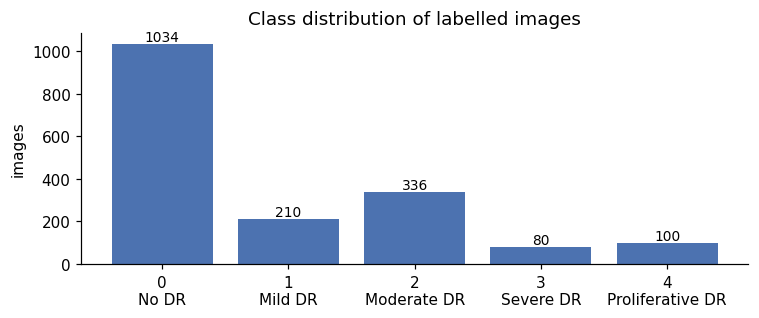

In [13]:
print_tree(dataset_path, max_depth=1)
print()
labels_df, discovery_info = discover_dataset(dataset_path, DATASET_OVERRIDES)

counts = labels_df.label.value_counts().sort_index()
assert set(counts.index) == set(GRADE_NAMES), f'Expected grades 0-4, found {sorted(counts.index)}'
dist = pd.DataFrame({'grade': [GRADE_NAMES[g] for g in counts.index], 'n_images': counts.values,
                     'percent': (100 * counts / counts.sum()).round(2).values}, index=counts.index)
display(dist)
print(f'Imbalance ratio (largest/smallest grade): {counts.max() / counts.min():.1f}')
HAS_PATIENT_IDS = 'patient_id' in labels_df.columns
if not HAS_PATIENT_IDS:
    display(Markdown('> **Limitation:** no patient identifier was found, so images from the same patient '
                     '(e.g. left/right eyes, repeat visits) cannot be kept in one split. Splitting is '
                     'stratified at image level, with exact/near-duplicate clusters kept together.'))
display(Markdown(f"Label semantics: the `{discovery_info.get('label_col', 'folder')}` values are integers 0–4. "
                 'For the APTOS-2019 data these are documented as the ICDR severity scale '
                 '(0 No DR … 4 Proliferative DR). Confirm this against the dataset documentation for any other source.'))

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([f'{g}\n{GRADE_NAMES[g]}' for g in counts.index], counts.values, color='#4C72B0')
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('images'); ax.set_title('Class distribution of labelled images')
plt.tight_layout(); plt.savefig(FIG_DIR / 'class_distribution.png', bbox_inches='tight'); plt.show()

## 5 · Standardised image cache (shared by all experiments)
Every image is decoded once, the dark background is cropped to the fundus bounding box
(pixels with max-channel intensity > 10), the crop is zero-padded to a square and resized to
256×256 with area interpolation. This geometric standardisation is **common to all five
experiments, including the baseline**; it removes variable black borders and aspect ratios but
applies no filtering. The cache also records an MD5 of the raw file bytes and perceptual
hashes for duplicate detection. Unreadable files are reported and excluded explicitly.

Loading existing standardised cache from Drive ...
Readable images: 1760 | unreadable (excluded): 0
Fundus crop applied to 1760 images; original sizes ranged 660-3338 px wide.


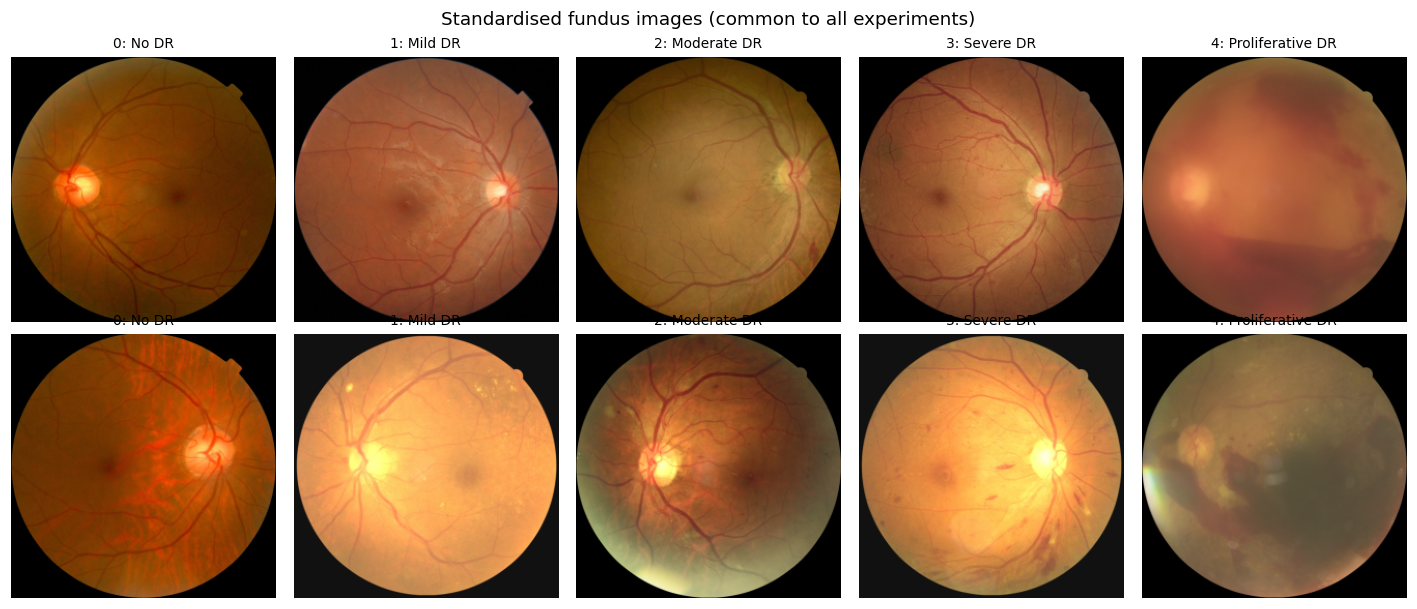

In [14]:
STD_PARAMS = dict(PP.DEFAULT_STANDARDISATION, cache_size=PROTOCOL['cache_size'],
                  crop_threshold=PROTOCOL['crop_threshold'])
S = STD_PARAMS['cache_size']
ids_fingerprint = hashlib.sha256('\n'.join(labels_df.image_id).encode()).hexdigest()[:16]
cache_tag = f'standardised_{S}_{ids_fingerprint}'
drive_npy, drive_idx = SHARED_CACHE / f'{cache_tag}.npy', SHARED_CACHE / f'{cache_tag}_index.csv'
local_npy = LOCAL_CACHE / f'{cache_tag}.npy'

def _process_one(i_path):
    i, path = i_path
    rec = dict(row=i, readable=False, md5=None, phash=None, dhash=None, error=None)
    try:
        b = PP.read_bytes(path)
        rec['md5'] = PP.md5_bytes(b)
        rgb = PP.decode_rgb(b)
        if rgb is None:
            rec['error'] = 'decode failed'
            return rec, None
        std, meta = PP.standardise(rgb, **STD_PARAMS)
        gray = Image.fromarray(cv2.cvtColor(std, cv2.COLOR_RGB2GRAY))
        rec.update(meta, readable=True, phash=str(imagehash.phash(gray)), dhash=str(imagehash.dhash(gray)))
        return rec, std
    except Exception as e:  # noqa: BLE001
        rec['error'] = f'{type(e).__name__}: {e}'
        return rec, None

if drive_npy.exists() and drive_idx.exists():
    print('Loading existing standardised cache from Drive ...')
    if not local_npy.exists():
        shutil.copy(drive_npy, local_npy)
    STD = np.load(local_npy)
    cache_index = pd.read_csv(drive_idx, dtype={'phash': str, 'dhash': str, 'md5': str})
    assert len(cache_index) == len(labels_df) == len(STD) and (cache_index.image_id == labels_df.image_id).all(), \
        'Cache does not match the labelled image list; delete the shared_cache folder to rebuild.'
else:
    print(f'Building standardised cache for {len(labels_df)} images (one-off, shared by all notebooks) ...')
    STD = np.lib.format.open_memmap(local_npy, mode='w+', dtype=np.uint8, shape=(len(labels_df), S, S, 3))
    records, t0 = [], time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        for k, (rec, img) in enumerate(ex.map(_process_one, enumerate(labels_df.path))):
            records.append(rec)
            STD[rec['row']] = img if img is not None else 0
            if (k + 1) % 500 == 0:
                print(f'  {k + 1}/{len(labels_df)} images ({time.time() - t0:.0f}s)')
    STD.flush()
    cache_index = pd.DataFrame(records).sort_values('row').reset_index(drop=True)
    cache_index.insert(0, 'image_id', labels_df.image_id.values)
    cache_index['label'] = labels_df.label.values
    shutil.copy(local_npy, drive_npy)
    cache_index.to_csv(drive_idx, index=False)
    STD = np.load(local_npy)
    print(f'Cache built in {time.time() - t0:.0f}s and saved to {SHARED_CACHE}')

unreadable = cache_index[~cache_index.readable]
print(f'Readable images: {cache_index.readable.sum()} | unreadable (excluded): {len(unreadable)}')
if len(unreadable):
    display(unreadable[['image_id', 'error']])
print(f"Fundus crop applied to {cache_index.cropped.fillna(False).astype(bool).sum()} images; "
      f"original sizes ranged {int(cache_index.orig_w.min())}-{int(cache_index.orig_w.max())} px wide.")

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
rng_vis = np.random.default_rng(0)
for g in range(5):
    rows = np.where((cache_index.label == g) & cache_index.readable)[0]
    for r in range(2):
        ax = axes[r, g]; ax.axis('off')
        if len(rows) > r:
            ax.imshow(STD[rng_vis.choice(rows)]); ax.set_title(f'{g}: {GRADE_NAMES[g]}', fontsize=9)
plt.suptitle('Standardised fundus images (common to all experiments)'); plt.tight_layout()
plt.savefig(FIG_DIR / 'standardised_examples.png', bbox_inches='tight'); plt.show()

## 6 · Duplicate detection and leakage prevention
* **Exact duplicates:** identical MD5 of raw file bytes.
* **Near duplicates (two-stage):** (1) *candidates* — perceptual hash (pHash) **and** difference
  hash (dHash) of the standardised greyscale image both within Hamming distance ≤ 8 of 64 bits;
  (2) *confirmation* — normalised cross-correlation ≥ 0.90 between high-pass green-channel
  signatures (vessel pattern) inside the fundus mask. Global hashes alone collide for different
  fundi because all fundus photographs share the same layout (bright disc, dark macula, circular
  field); the vessel-pattern check is specific to the individual eye/photograph. Confirmed and
  closest rejected pairs are shown below for visual verification.
* Duplicate images are linked into clusters (union–find). A cluster whose members carry
  **different grades** is a label conflict and is excluded entirely (it cannot be graded
  reliably). For clusters with consistent grades a single representative (largest original
  resolution) is kept so that the same eye is neither double-counted nor split across sets.
* Every exclusion is written to `shared_splits/excluded_images.csv`.

Hash candidates: 4800 | confirmed by vessel-pattern NCC >= 0.9: 5
NCC of candidate pairs (quantiles 0/25/50/75/100%): [-0.182, 0.01, 0.053, 0.111, 1.0]
Exact-duplicate files (beyond first copy): 4
Duplicate pairs linked (exact + confirmed near): 9 | images in duplicate clusters: 10 | largest cluster: 2
Conflicting-grade duplicate clusters: 0 (0 images excluded)
Images retained for the study: 1755 of 1760 labelled; excluded: 5


,excluded images
category,
redundant duplicate (same grade),5


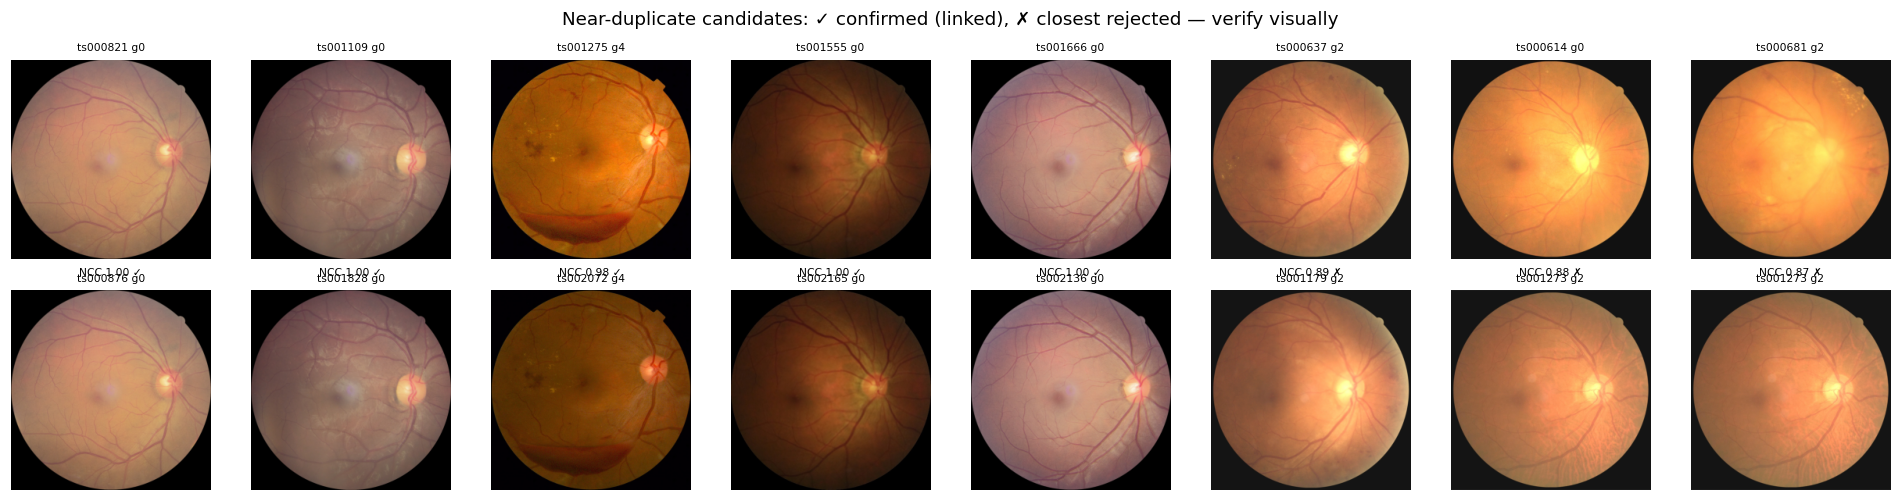

In [15]:
readable = cache_index[cache_index.readable].copy()

def hex_to_uint64(hs):
    return np.array([int(h, 16) for h in hs], dtype=np.uint64)

def popcount64(x):
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    return np.unpackbits(x.view(np.uint8).reshape(*x.shape, 8), axis=-1).sum(-1)

ph, dh = hex_to_uint64(readable.phash), hex_to_uint64(readable.dhash)
T_HAM = PROTOCOL['near_duplicate_hamming']
T_NCC = PROTOCOL['near_duplicate_ncc']
candidates = []
for i0 in range(0, len(ph), 512):
    dp = popcount64(ph[i0:i0 + 512, None] ^ ph[None, :])
    dd = popcount64(dh[i0:i0 + 512, None] ^ dh[None, :])
    ii, jj = np.where((dp <= T_HAM) & (dd <= T_HAM))
    keep = (ii + i0) < jj
    candidates += [(int(a + i0), int(b), int(dp[a, b]), int(dd[a, b])) for a, b in zip(ii[keep], jj[keep])]
_sig_cache = {}
def sig(pos):
    if pos not in _sig_cache:
        _sig_cache[pos] = PP.detail_signature(STD[int(readable.iloc[pos].row)])
    return _sig_cache[pos]
cand_df = pd.DataFrame(candidates, columns=['a', 'b', 'phash_d', 'dhash_d'])
cand_df['ncc'] = [float(sig(a) @ sig(b)) for a, b in zip(cand_df.a, cand_df.b)] if len(cand_df) else []
confirmed = cand_df[cand_df.ncc >= T_NCC]
pairs = [tuple(r) for r in confirmed[['a', 'b', 'phash_d', 'dhash_d']].astype(int).itertuples(index=False)]
print(f'Hash candidates: {len(cand_df)} | confirmed by vessel-pattern NCC >= {T_NCC}: {len(confirmed)}')
if len(cand_df):
    print('NCC of candidate pairs (quantiles 0/25/50/75/100%):', np.round(np.quantile(cand_df.ncc, [0, .25, .5, .75, 1]), 3).tolist())
md5_groups = readable.groupby('md5').indices
for idxs in md5_groups.values():
    idxs = list(idxs)
    pairs += [(idxs[0], j, -1, -1) for j in idxs[1:]]

parent = list(range(len(readable)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for a, b, *_ in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[max(ra, rb)] = min(ra, rb)
readable['dup_cluster'] = [find(i) for i in range(len(readable))]

if HAS_PATIENT_IDS:   # images of one patient must also share a split
    pmap = labels_df.set_index('image_id').patient_id
    readable['patient_id'] = readable.image_id.map(pmap)
    for _, idx in readable.groupby('patient_id').indices.items():
        for j in idx[1:]:
            ra, rb = find(idx[0]), find(j)
            if ra != rb: parent[max(ra, rb)] = min(ra, rb)
    readable['group_cluster'] = [find(i) for i in range(len(readable))]
else:
    readable['group_cluster'] = readable.dup_cluster

csize = readable.dup_cluster.map(readable.dup_cluster.value_counts())
n_exact = sum(len(v) - 1 for v in md5_groups.values() if len(v) > 1)
print(f'Exact-duplicate files (beyond first copy): {n_exact}')
print(f'Duplicate pairs linked (exact + confirmed near): {len(pairs)} | images in duplicate clusters: {(csize > 1).sum()} '
      f'| largest cluster: {csize.max()}')
if csize.max() > 20:
    print('WARNING: a very large duplicate cluster suggests hash collisions; inspect the pairs below '
          'and consider lowering near_duplicate_hamming (this changes the protocol for ALL notebooks).')

labels_per_cluster = readable.groupby('dup_cluster').label.nunique()
conflict_clusters = set(labels_per_cluster[labels_per_cluster > 1].index)
excluded = [dict(image_id=r.image_id, label=r.label, category='unreadable file', reason=str(r.error))
            for r in unreadable.itertuples()]
kept_rows = []
for cl, grp in readable.groupby('dup_cluster'):
    if cl in conflict_clusters:
        excluded += [dict(image_id=r.image_id, label=r.label, category='duplicate with conflicting grades',
                          reason=f'cluster grades {sorted(int(v) for v in grp.label.unique())}') for r in grp.itertuples()]
    elif len(grp) > 1:
        rep = grp.assign(area=grp.orig_h * grp.orig_w).sort_values(['area', 'image_id'], ascending=[False, True]).iloc[0]
        kept_rows.append(rep.name)
        excluded += [dict(image_id=r.image_id, label=r.label, category='redundant duplicate (same grade)',
                          reason=f'duplicate of {rep.image_id}') for r in grp.itertuples() if r.Index != rep.name]
    else:
        kept_rows.append(grp.index[0])
clean = readable.loc[sorted(kept_rows)].copy()
excluded_df = pd.DataFrame(excluded, columns=['image_id', 'label', 'category', 'reason'])
print(f'Conflicting-grade duplicate clusters: {len(conflict_clusters)} '
      f'({readable.dup_cluster.isin(conflict_clusters).sum()} images excluded)')
print(f'Images retained for the study: {len(clean)} of {len(labels_df)} labelled; excluded: {len(excluded_df)}')
display(excluded_df.category.value_counts().rename('excluded images').to_frame())

show = [(int(r.a), int(r.b), f'NCC {r.ncc:.2f} ✓') for r in confirmed.head(6).itertuples()]
show += [(int(r.a), int(r.b), f'NCC {r.ncc:.2f} ✗') for r in cand_df[cand_df.ncc < T_NCC].sort_values('ncc', ascending=False).head(3).itertuples()]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 4.6))
    axes = np.array(axes).reshape(2, -1)
    for k, (a, b, lab) in enumerate(show):
        for r, idx in enumerate((a, b)):
            row = readable.iloc[idx]
            axes[r, k].imshow(STD[int(row.row)]); axes[r, k].axis('off')
            axes[r, k].set_title(f'{row.image_id[:8]} g{row.label}', fontsize=7)
        axes[0, k].text(0.5, -0.08, lab, transform=axes[0, k].transAxes, ha='center', fontsize=7)
    plt.suptitle('Near-duplicate candidates: ✓ confirmed (linked), ✗ closest rejected — verify visually'); plt.tight_layout()
    plt.savefig(FIG_DIR / 'near_duplicate_pairs.png', bbox_inches='tight'); plt.show()

## 7 · Fixed, reproducible train / validation / test split (shared by all notebooks)
The first notebook to run creates `shared_splits/split_manifest.csv`; every other notebook
**loads and verifies** it (dataset fingerprint, protocol settings, absence of group overlap).
Splitting is stratified by grade (≈70/15/15). When patient identifiers or multi-image clusters
exist, `StratifiedGroupKFold` keeps each group within one split. With ~3,600 images, a single
held-out test set of ~550 images (≥25 images in the rarest grade) is large enough for
bootstrap confidence intervals, while repeated training runs make k-fold cross-validation of
9 runs × 5 experiments impractical on Colab — this trade-off is disclosed as a limitation.
**The test split is used only after model selection (section 15).**

In [16]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

dataset_fingerprint = hashlib.sha256('\n'.join(f'{r.image_id}:{r.md5}:{r.label}' for r in clean.itertuples()).encode()).hexdigest()[:16]
split_settings = dict(fractions=PROTOCOL['split_fractions'], seed=PROTOCOL['split_seed'],
                      near_duplicate_hamming=T_HAM, near_duplicate_ncc=T_NCC, duplicate_policy=PROTOCOL['duplicate_policy'],
                      conflicting_duplicate_policy=PROTOCOL['conflicting_duplicate_policy'])
manifest_path, split_meta_path = SPLIT_DIR / 'split_manifest.csv', SPLIT_DIR / 'split_meta.json'

def make_split(df, fr, seed):
    y, groups = df.label.values, df.group_cluster.values
    if len(np.unique(groups)) == len(groups):
        idx = np.arange(len(df))
        tv, te = train_test_split(idx, test_size=fr['test'], stratify=y, random_state=seed)
        tr, va = train_test_split(tv, test_size=fr['val'] / (1 - fr['test']), stratify=y[tv], random_state=seed)
        method = 'stratified image-level (train_test_split); duplicate clusters already collapsed'
    else:
        sg = StratifiedGroupKFold(n_splits=max(2, round(1 / fr['test'])), shuffle=True, random_state=seed)
        tv, te = next(sg.split(np.zeros(len(y)), y, groups))
        sg2 = StratifiedGroupKFold(n_splits=max(2, round((1 - fr['test']) / fr['val'])), shuffle=True, random_state=seed)
        a, b = next(sg2.split(np.zeros(len(tv)), y[tv], groups[tv]))
        tr, va = tv[a], tv[b]
        method = 'StratifiedGroupKFold (groups = patient / duplicate clusters)'
    split = np.empty(len(df), dtype=object)
    split[tr], split[va], split[te] = 'train', 'val', 'test'
    return split, method

if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    meta = json.loads(split_meta_path.read_text())
    problems = []
    if meta['dataset_fingerprint'] != dataset_fingerprint: problems.append('dataset fingerprint differs')
    if meta['settings'] != to_jsonable(split_settings): problems.append('split settings differ')
    if set(manifest.image_id) != set(clean.image_id): problems.append('image set differs')
    if problems:
        raise RuntimeError('Saved split is inconsistent with this run: ' + '; '.join(problems) +
                           f'. If the dataset/protocol was changed intentionally, delete {SPLIT_DIR} and rerun ALL notebooks.')
    print(f"Loaded shared split created by {meta['created_by']} on {meta['created_at']} (manifest sha {meta['manifest_sha256'][:12]})")
else:
    split, split_method = make_split(clean.reset_index(drop=True), PROTOCOL['split_fractions'], PROTOCOL['split_seed'])
    manifest = clean.reset_index(drop=True)[['image_id', 'label', 'md5', 'dup_cluster', 'group_cluster']].copy()
    manifest['split'] = split
    manifest.to_csv(manifest_path, index=False)
    excluded_df.to_csv(SPLIT_DIR / 'excluded_images.csv', index=False)
    meta = dict(created_by=EXPERIMENT_ID, created_at=time.strftime('%Y-%m-%d %H:%M:%S'), method=split_method,
                settings=split_settings, dataset_fingerprint=dataset_fingerprint,
                manifest_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
                patient_ids_available=HAS_PATIENT_IDS,
                discovery={k: (v[:100] if isinstance(v, list) else v) for k, v in discovery_info.items()},
                n_retained=len(manifest), n_excluded=len(excluded_df))
    save_json(meta, split_meta_path)
    print(f'Created and saved new shared split: {split_method}')

SPLIT_SHA = hashlib.sha256(manifest_path.read_bytes()).hexdigest()[:12]
manifest = manifest.merge(readable[['image_id', 'row']], on='image_id', how='left')
assert manifest.row.notna().all()
# --- leakage checks ---
for col in ('group_cluster', 'md5', 'dup_cluster'):
    n_split = manifest.groupby(col).split.nunique()
    assert (n_split == 1).all(), f'LEAKAGE: {col} spans several splits'
assert manifest.image_id.is_unique
print('Leakage checks passed: no image, file hash, duplicate cluster or patient group spans two splits.')

tab = pd.crosstab(manifest.label.map(lambda g: f'{g} {GRADE_NAMES[g]}'), manifest.split)[['train', 'val', 'test']]
tab.loc['total'] = tab.sum()
display(tab)
min_eval = tab.drop('total')[['val', 'test']].values.min()
if min_eval < 10:
    raise RuntimeError(f'A grade has only {min_eval} images in val/test: estimates would be unreliable. '
                       'Use a larger dataset or switch to stratified k-fold cross-validation.')
print(f'Split hash: {SPLIT_SHA}')

Loaded shared split created by 01_Wavelet on 2026-10-20 06:13:20 (manifest sha c451a93a3681)
Leakage checks passed: no image, file hash, duplicate cluster or patient group spans two splits.


split,train,val,test
label,,,
0 No DR,720,155,155
1 Mild DR,147,31,32
2 Moderate DR,235,51,50
3 Severe DR,56,12,12
4 Proliferative DR,69,15,15
total,1227,264,264


Split hash: c451a93a3681


## 8 · Preprocessing: green-channel extraction
**Method:** the green channel (RGB index 1) of the 256×256 standardised image is extracted and
**replicated into three identical channels** (H×W×3, uint8). No other change is made.

*Rationale:* in colour fundus photographs the green channel usually shows the highest contrast for
blood vessels and red lesions (haemoglobin absorbs green light strongly), which is why it is widely
used in retinal image analysis (e.g. reviewed by Fraz et al., 2012). *Risk:* red and blue information is
discarded, including colour cues that distinguish hard exudates, cotton-wool spots and the optic disc.

*Compatibility with ImageNet models:* all four networks expect 3-channel input, so the single channel
is replicated; the batch-shape assertion in section 9 confirms tensors of shape (B, 3, 224, 224) for
every architecture. After ImageNet normalisation the three copies differ by per-channel mean/std.
Only brightness/contrast jitter is used in augmentation, so the copies stay identical before
normalisation. The detail-retention metric on the green channel is 1.0 by construction (the green
channel is unchanged); information loss here is chromatic, not spatial.

Preprocessing method: green_channel
Parameters: {
  "source_channel": "G (RGB index 1)",
  "replicate_to": 3
}
Preprocessed 1755 images in 0.4s (0.20 ms/image at 256x256)


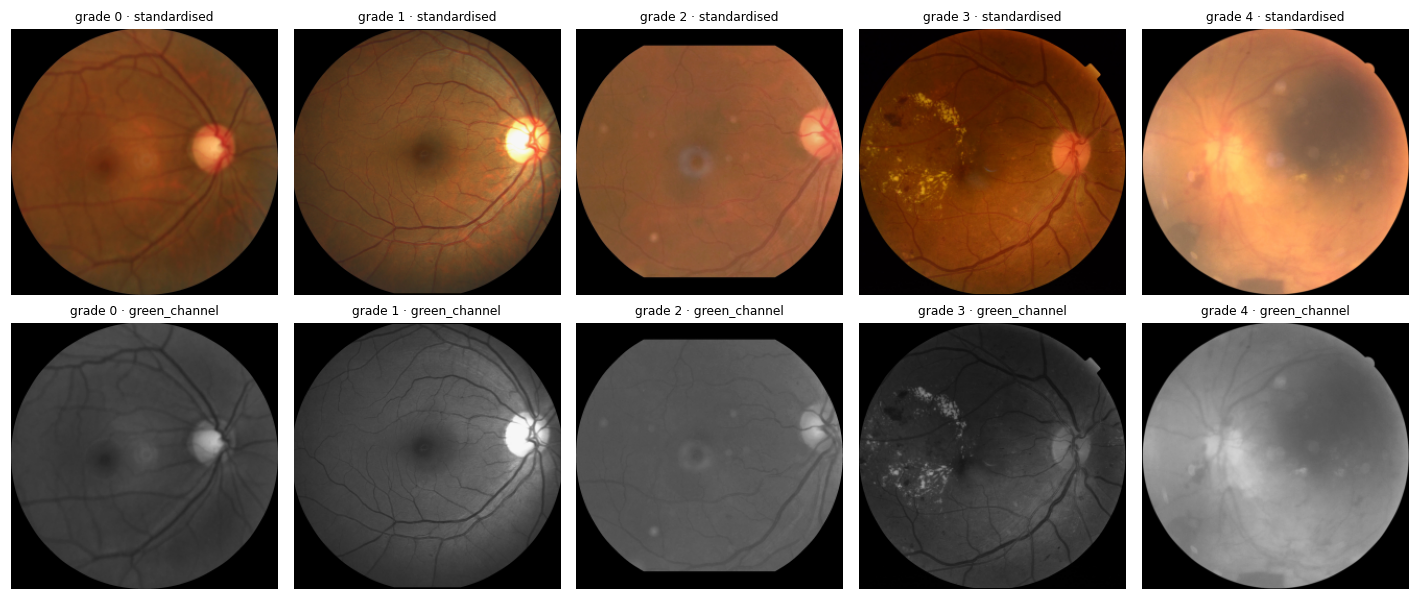

Fine-detail retention (green channel, inside fundus mask; 1.0 = unchanged):
{
  "laplacian_var_ratio_green_mean": 1.0,
  "laplacian_var_ratio_green_sd": 0.0,
  "psnr_green_median": Infinity,
  "n_images": 200
}


In [17]:
METHOD_PARAMS = PP.DEFAULT_PARAMS[PREPROCESSING_METHOD]
print(f'Preprocessing method: {PREPROCESSING_METHOD}\nParameters: {json.dumps(METHOD_PARAMS, indent=2)}')

order = {'train': 0, 'val': 1, 'test': 2}
manifest = manifest.sort_values(['split', 'image_id'], key=lambda s: s.map(order) if s.name == 'split' else s).reset_index(drop=True)
t0 = time.time()
X = np.empty((len(manifest), S, S, 3), dtype=np.uint8)
for i, r in enumerate(manifest.row.astype(int).values):
    X[i] = PP.apply_preprocessing(STD[r], PREPROCESSING_METHOD, METHOD_PARAMS)
PREPROC_SECONDS = time.time() - t0
print(f'Preprocessed {len(X)} images in {PREPROC_SECONDS:.1f}s ({1000 * PREPROC_SECONDS / len(X):.2f} ms/image at {S}x{S})')
Y = manifest.label.values.astype(int)
IDX = {s: np.where(manifest.split.values == s)[0] for s in ('train', 'val', 'test')}
GROUPS_TEST = manifest.group_cluster.values[IDX['test']]

# visual comparison: one training image per grade, standardised vs preprocessed
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for g in range(5):
    i = IDX['train'][Y[IDX['train']] == g][0]
    axes[0, g].imshow(STD[int(manifest.row[i])]); axes[0, g].set_title(f'grade {g} · standardised', fontsize=8)
    axes[1, g].imshow(X[i]); axes[1, g].set_title(f'grade {g} · {PREPROCESSING_METHOD}', fontsize=8)
    for a in axes[:, g]: a.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / 'preprocessing_examples.png', bbox_inches='tight'); plt.show()

# information-retention diagnostics on a fixed sample of TRAINING images only
sample = np.random.default_rng(0).choice(IDX['train'], size=min(200, len(IDX['train'])), replace=False)
ret = np.array([PP.detail_retention(STD[int(manifest.row[i])], X[i]) for i in sample])
DETAIL_RETENTION = dict(laplacian_var_ratio_green_mean=float(np.nanmean(ret[:, 0])),
                        laplacian_var_ratio_green_sd=float(np.nanstd(ret[:, 0])),
                        psnr_green_median=float(np.median(ret[:, 1])) if np.isfinite(ret[:, 1]).any() else float('inf'),
                        n_images=len(sample))
print('Fine-detail retention (green channel, inside fundus mask; 1.0 = unchanged):')
print(json.dumps(DETAIL_RETENTION, indent=2))
save_json(dict(method=PREPROCESSING_METHOD, params=METHOD_PARAMS, standardisation=STD_PARAMS,
               seconds_total=PREPROC_SECONDS, n_images=len(X), detail_retention=DETAIL_RETENTION), EXP_DIR / 'preprocessing_record.json')

## 9 · Dataset, augmentation and class-imbalance pipeline
**Training only:** random resized crop (scale 0.85–1.0, near-square aspect), horizontal flip
(left/right eyes are mirror images, so flipping produces anatomically plausible fundi),
rotation ±15° (camera/head tilt), brightness/contrast ±10% (illumination variation). No hue or
saturation jitter is used, which also keeps the replicated green-channel images grey.
**Validation/test:** deterministic resize 256→224 only.
**Normalisation:** ImageNet mean/std on all three channels, as expected by the pretrained
weights. For the green-channel experiment the three identical channels are normalised with
different per-channel statistics, so they are no longer numerically identical after
normalisation — a standard, documented consequence of reusing RGB-pretrained filters.
**Class imbalance:** a single technique — class-weighted cross-entropy with weights
w_k = N / (K·n_k) from training-split counts. A weighted sampler is *not* combined with it
(double correction would over-weight rare grades).

,grade,train_count,loss_weight
0,No DR,720,0.341
1,Mild DR,147,1.669
2,Moderate DR,235,1.044
3,Severe DR,56,4.382
4,Proliferative DR,69,3.557


Batch tensor shape: (32, 3, 224, 224) | dtype torch.float32


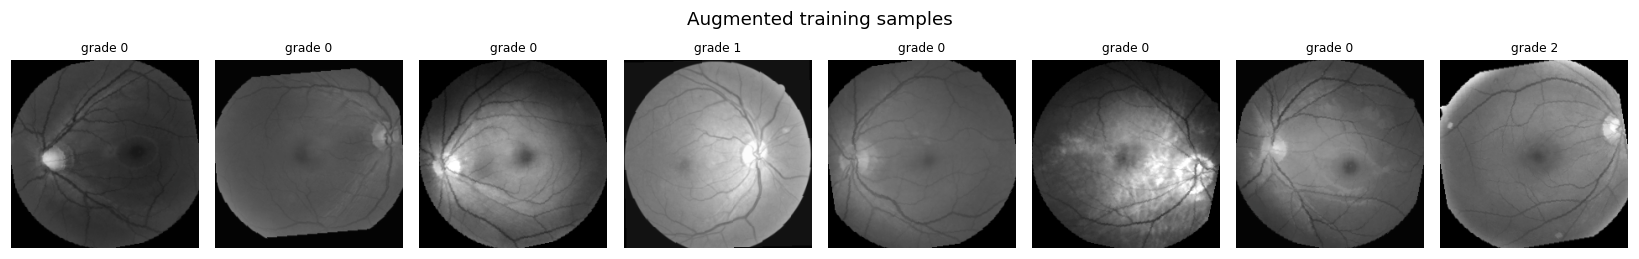

In [18]:
AUG = PROTOCOL['augmentation']
IMG = PROTOCOL['image_size']
train_tf = PP.build_train_transform(IMG, AUG)
eval_tf = PP.build_eval_transform(IMG)

class ArrayDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); random.seed(s)

def make_loader(split, train, seed):
    ds = ArrayDataset(X[IDX[split]], Y[IDX[split]], train_tf if train else eval_tf)
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=PROTOCOL['batch_size'], shuffle=train, drop_last=train,
                      num_workers=RUN_OPTIONS['num_workers'], pin_memory=DEVICE.type == 'cuda',
                      worker_init_fn=seed_worker, generator=g, persistent_workers=False)

n_k = np.bincount(Y[IDX['train']], minlength=5)
CLASS_WEIGHTS = len(IDX['train']) / (5 * n_k)
display(pd.DataFrame({'grade': [GRADE_NAMES[k] for k in range(5)], 'train_count': n_k,
                      'loss_weight': CLASS_WEIGHTS.round(3)}))

xb, yb = next(iter(make_loader('train', True, 0)))
assert xb.shape[1:] == (3, IMG, IMG), xb.shape
print('Batch tensor shape:', tuple(xb.shape), '| dtype', xb.dtype)
mean, std = torch.tensor(PP.IMAGENET_MEAN).view(3, 1, 1), torch.tensor(PP.IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(15, 2.4))
for k in range(8):
    axes[k].imshow((xb[k] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()); axes[k].axis('off')
    axes[k].set_title(f'grade {int(yb[k])}', fontsize=8)
plt.suptitle('Augmented training samples'); plt.tight_layout()
plt.savefig(FIG_DIR / 'augmented_samples.png', bbox_inches='tight'); plt.show()

## 10 · Pretrained architectures
All four use torchvision `IMAGENET1K_V1` weights (the same file in every notebook). The original
1000-class classifier is removed and replaced by a newly initialised 5-class linear layer.
**Transfer-learning strategy (identical for all):** (i) 2 epochs with the backbone frozen and
BatchNorm statistics fixed, training only CBAM + head (lr 1e-3), so the random head does not
corrupt pretrained features; (ii) full fine-tuning with discriminative learning rates
(backbone 1e-4, head/attention 1e-3), AdamW, cosine decay over 30 epochs, early stopping
(patience 6) on validation QWK. Hyper-parameters are fixed a priori from common
transfer-learning practice and are **not tuned per preprocessing method**, which is what keeps
the comparison controlled; no test data is used for any choice.

In [19]:
ALLOW_RANDOM_INIT = SMOKE_TEST   # never True in a real run
arch_rows = []
for arch in PROTOCOL['architectures']:
    for att in ('cbam', 'none'):
        m, prov = MD.build_model(arch, attention=att, reduction=PROTOCOL['cbam_reduction'],
                                 spatial_kernel=PROTOCOL['cbam_spatial_kernel'], dropout=PROTOCOL['head_dropout'],
                                 pretrained=True, allow_random_init=ALLOW_RANDOM_INIT)
        with torch.no_grad():
            out = m.eval()(torch.zeros(1, 3, IMG, IMG))
        assert out.shape == (1, 5)
        arch_rows.append(dict(architecture=arch, attention=att, weights=prov['weights'],
                              pretrained_loaded=prov['pretrained_loaded'], feature_channels=prov['feature_channels'],
                              params_total_M=prov['params_total'] / 1e6, params_backbone_M=prov['params_backbone'] / 1e6,
                              params_new=prov['params_new']))
        del m
arch_table = pd.DataFrame(arch_rows)
display(arch_table.round(3))
if not ALLOW_RANDOM_INIT and not arch_table.pretrained_loaded.all():
    raise RuntimeError('Some pretrained weights failed to load; the protocol requires ImageNet initialisation.')
arch_table.to_csv(EXP_DIR / 'architectures.csv', index=False)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 182MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 124MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 179MB/s] 


,architecture,attention,weights,pretrained_loaded,feature_channels,params_total_M,params_backbone_M,params_new
0,EfficientNetB0,cbam,EfficientNet_B0_Weights.IMAGENET1K_V1,True,1280,4.219,4.008,211303
1,EfficientNetB0,none,EfficientNet_B0_Weights.IMAGENET1K_V1,True,1280,4.014,4.008,6405
2,ResNet50,cbam,ResNet50_Weights.IMAGENET1K_V1,True,2048,24.043,23.508,534631
3,ResNet50,none,ResNet50_Weights.IMAGENET1K_V1,True,2048,23.518,23.508,10245
4,DenseNet121,cbam,DenseNet121_Weights.IMAGENET1K_V1,True,1024,7.090,6.954,136295
5,DenseNet121,none,DenseNet121_Weights.IMAGENET1K_V1,True,1024,6.959,6.954,5125
6,ConvNeXtTiny,cbam,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,True,768,27.898,27.819,79207
7,ConvNeXtTiny,none,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,True,768,27.824,27.819,5381


## 11 · Attention mechanism: CBAM
The **Convolutional Block Attention Module** (Woo et al., 2018) refines a feature map
F ∈ ℝ^{C×H×W} in two steps:
1. **Channel attention** M_c = σ(MLP(AvgPool(F)) + MLP(MaxPool(F))) — a shared two-layer
   bottleneck (reduction r = 16) re-weights *which* feature channels matter (e.g. channels
   responding to red lesions or bright exudates).
2. **Spatial attention** M_s = σ(conv₇ₓ₇([mean_c(F'); max_c(F')])) re-weights *where* in
   the image to look, which may help emphasise small, sparse lesions (microaneurysms,
   haemorrhages) against a large, mostly normal retina.

**Insertion point (identical for all four architectures):** after the final pretrained
stage and before global average pooling. This keeps every pretrained weight intact
(CBAM is new and trainable), applies the same policy to all networks, and adds only
0.08–0.5 M parameters. A deeper per-block insertion would alter pretrained activations
inside the network and is architecture-specific, so it was not used.
*Caveat:* EfficientNet-B0 already contains Squeeze-and-Excitation blocks as part of its
original design; "NoAttn" therefore means *no added attention*, not attention-free.

Models labelled `cbam_*` contain CBAM in the forward pass during training and inference;
models labelled `noattn_*` are the same architecture with CBAM replaced by an identity
(used for the controlled ablation in section 17).

In [20]:
cb = MD.CBAM(64, reduction=PROTOCOL['cbam_reduction'], spatial_kernel=PROTOCOL['cbam_spatial_kernel'])
f = torch.randn(2, 64, 7, 7)
o = cb(f)
print('CBAM check: in', tuple(f.shape), '-> out', tuple(o.shape), '| spatial map', tuple(cb.last_spatial_map.shape),
      '| params', sum(p.numel() for p in cb.parameters()))
m_tmp, _ = MD.build_model('ResNet50', attention='cbam', pretrained=False)
assert any(isinstance(mod, MD.CBAM) for mod in m_tmp.modules()), 'CBAM not present in the forward graph'
m_tmp2, _ = MD.build_model('ResNet50', attention='none', pretrained=False)
assert not any(isinstance(mod, MD.CBAM) for mod in m_tmp2.modules())
del m_tmp, m_tmp2
print('Verified: cbam variants contain CBAM modules, noattn variants do not.')

CBAM check: in (2, 64, 7, 7) -> out (2, 64, 7, 7) | spatial map (2, 1, 7, 7) | params 1122
Verified: cbam variants contain CBAM modules, noattn variants do not.


## 12 · Training engine
Per epoch: training loss/accuracy, then validation loss, accuracy, macro F1 and QWK. The
checkpoint with the best validation QWK (the pre-declared primary metric) is saved; early
stopping monitors the same metric. A resume checkpoint (model, optimiser, scheduler,
AMP scaler, RNG states, history) is written each epoch so that interrupted runs continue.
Gradients are clipped (L2 norm 1.0) and mixed precision is used on GPU.

In [21]:
PRIMARY = PROTOCOL['primary_metric']

@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    probs, labels, loss_sum, n = [], [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(xb)
        logits = logits.float()
        if criterion is not None:
            loss_sum += criterion(logits, yb).item() * len(yb); n += len(yb)
        probs.append(torch.softmax(logits, 1).cpu().numpy()); labels.append(yb.cpu().numpy())
    return np.concatenate(probs), np.concatenate(labels), (loss_sum / n if n else float('nan'))

def quick_scores(y, prob):
    cm = MT.cm_fast(y, prob.argmax(1))
    return dict(acc=MT.accuracy_from_cm(cm), macro_f1=MT.macro_f1_from_cm(cm), qwk=MT.qwk_from_cm(cm))

def run_name(arch, attention, seed):
    return EXP_DIR / arch / f"{'cbam' if attention == 'cbam' else 'noattn'}_seed{seed}"

def train_run(arch, attention='cbam', seed=42):
    rdir = run_name(arch, attention, seed); rdir.mkdir(parents=True, exist_ok=True)
    done_file, last_ckpt, best_file = rdir / 'run_complete.json', rdir / 'last_checkpoint.pt', rdir / 'best_model.pt'
    if done_file.exists() and not RUN_OPTIONS['force_retrain']:
        print(f'[skip] {rdir.relative_to(OUTPUT_ROOT)} already complete')
        return json.loads(done_file.read_text())
    set_seed(seed)
    model, prov = MD.build_model(arch, attention=attention, reduction=PROTOCOL['cbam_reduction'],
                                 spatial_kernel=PROTOCOL['cbam_spatial_kernel'], dropout=PROTOCOL['head_dropout'],
                                 pretrained=True, allow_random_init=ALLOW_RANDOM_INIT)
    model = model.to(DEVICE).to(memory_format=torch.channels_last)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW([{'params': model.backbone.parameters(), 'lr': PROTOCOL['lr_backbone']},
                             {'params': model.head_parameters(), 'lr': PROTOCOL['lr_head']}],
                            weight_decay=PROTOCOL['weight_decay'])
    E = PROTOCOL['max_epochs']
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: 0.5 * (1 + math.cos(math.pi * e / E)))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    train_loader, val_loader = make_loader('train', True, seed), make_loader('val', False, seed)
    hist, start, best, best_epoch, bad = [], 0, -float('inf'), -1, 0
    if last_ckpt.exists() and not RUN_OPTIONS['force_retrain']:
        ck = torch.load(last_ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['optimizer'])
        sched.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
        hist, start, best, best_epoch, bad = ck['history'], ck['epoch'] + 1, ck['best'], ck['best_epoch'], ck['bad']
        torch.set_rng_state(ck['rng_torch']); np.random.set_state(ck['rng_numpy']); random.setstate(ck['rng_python'])
        if DEVICE.type == 'cuda' and ck.get('rng_cuda') is not None: torch.cuda.set_rng_state_all(ck['rng_cuda'])
        train_loader.generator.set_state(ck['rng_loader'])
        print(f'[resume] {rdir.name} from epoch {start}')
    t_start = time.time() - (hist[-1]['elapsed_s'] if hist else 0.0)
    for epoch in range(start, E):
        frozen = epoch < PROTOCOL['warmup_frozen_epochs']
        MD.set_backbone_trainable(model, not frozen)
        model.train()
        if frozen: model.backbone.eval()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); yb = yb.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(xb); loss = criterion(logits.float(), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {epoch} in {rdir}')
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], PROTOCOL['grad_clip_norm'])
            scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (logits.argmax(1) == yb).sum().item(); tn += len(yb)
        sched.step()
        vp, vy, vloss = predict(model, val_loader, criterion)
        vs = quick_scores(vy, vp)
        rec = dict(epoch=epoch, frozen_backbone=frozen, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss,
                   val_acc=vs['acc'], val_macro_f1=vs['macro_f1'], val_qwk=vs['qwk'],
                   lr_backbone=opt.param_groups[0]['lr'], lr_head=opt.param_groups[1]['lr'],
                   elapsed_s=time.time() - t_start)
        hist.append(rec)
        score = vs[PRIMARY]
        improved = score > best + PROTOCOL['min_delta']
        if improved:
            best, best_epoch, bad = score, epoch, 0
            torch.save(model.state_dict(), best_file)
        elif not frozen:
            bad += 1
        print(f"  ep{epoch:02d} {'F' if frozen else ' '} loss {rec['train_loss']:.3f}/{vloss:.3f} "
              f"acc {rec['train_acc']:.3f}/{vs['acc']:.3f} vF1 {vs['macro_f1']:.3f} vQWK {vs['qwk']:.3f}"
              f"{'  *best' if improved else ''}  [{rec['elapsed_s'] / 60:.1f} min]")
        torch.save(dict(model=model.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch, history=hist, best=best, best_epoch=best_epoch, bad=bad,
                        rng_torch=torch.get_rng_state(), rng_numpy=np.random.get_state(), rng_python=random.getstate(),
                        rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None,
                        rng_loader=train_loader.generator.get_state()), last_ckpt)
        if bad >= PROTOCOL['early_stopping_patience']:
            print(f'  early stopping at epoch {epoch} (best epoch {best_epoch})'); break
    pd.DataFrame(hist).to_csv(rdir / 'history.csv', index=False)
    # final validation metrics of the selected (best) checkpoint
    model.load_state_dict(torch.load(best_file, map_location=DEVICE, weights_only=True))
    vp, vy, vloss = predict(model, val_loader, criterion)
    val_metrics = MT.compute_metrics(vy, vp, GRADE_NAMES); val_metrics['loss'] = vloss
    save_json(val_metrics, rdir / 'val_metrics.json')
    model_cfg = dict(prov, weights_file='best_model.pt', num_classes=5, grade_names=GRADE_NAMES,
                     class_to_index={GRADE_NAMES[k]: k for k in range(5)},
                     preprocessing_method=PREPROCESSING_METHOD, preprocessing_params=METHOD_PARAMS,
                     standardisation=STD_PARAMS, image_size=IMG, color_channels=(
                         'G replicated to 3 channels' if PREPROCESSING_METHOD == 'green_channel' else 'RGB'),
                     normalisation_mean=list(PP.IMAGENET_MEAN), normalisation_std=list(PP.IMAGENET_STD),
                     input_format='file path / bytes / RGB uint8 array of the ORIGINAL fundus photo',
                     experiment_id=EXPERIMENT_ID, seed=seed, best_epoch=best_epoch, protocol=PROTOCOL,
                     protocol_hash=PROTOCOL_HASH, split_sha=SPLIT_SHA, dr_lib_hash=LIB_HASH, environment=ENV)
    save_json(model_cfg, rdir / 'model_config.json')
    summary = dict(run_dir=str(rdir), architecture=arch, attention=attention, seed=seed, best_epoch=best_epoch,
                   epochs_run=len(hist), train_seconds=hist[-1]['elapsed_s'], best_val=val_metrics[PRIMARY],
                   val_qwk=val_metrics['qwk'], val_macro_f1=val_metrics['macro_f1'], val_accuracy=val_metrics['accuracy'],
                   pretrained_loaded=prov['pretrained_loaded'])
    save_json(summary, done_file)
    if not RUN_OPTIONS['keep_last_checkpoint'] and last_ckpt.exists():
        last_ckpt.unlink()
    del model, opt; torch.cuda.empty_cache() if DEVICE.type == 'cuda' else None
    return summary

## 13 · Train the four CBAM-augmented architectures (main experiment, seed 42)

In [22]:
MAIN_RUNS = {}
for arch in PROTOCOL['architectures']:
    print(f'\n=== {EXPERIMENT_ID} | {arch} | CBAM | seed {PROTOCOL["seed_main"]} ===')
    try:
        MAIN_RUNS[arch] = train_run(arch, 'cbam', PROTOCOL['seed_main'])
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError(f'GPU out of memory for {arch}. Reduce PROTOCOL batch_size in ALL notebooks '
                           '(a protocol change) or use a larger GPU.') from e
display(pd.DataFrame(MAIN_RUNS.values())[['architecture', 'best_epoch', 'epochs_run', 'train_seconds',
                                           'val_qwk', 'val_macro_f1', 'val_accuracy']].round(4))


=== 03_Green_Channel | EfficientNetB0 | CBAM | seed 42 ===
  ep00 F loss 1.447/1.397 acc 0.437/0.595 vF1 0.416 vQWK 0.551  *best  [0.2 min]
  ep01 F loss 1.233/1.306 acc 0.599/0.443 vF1 0.338 vQWK 0.626  *best  [0.3 min]
  ep02   loss 1.372/1.279 acc 0.475/0.549 vF1 0.382 vQWK 0.595  [0.5 min]
  ep03   loss 1.112/1.216 acc 0.582/0.636 vF1 0.432 vQWK 0.664  *best  [0.6 min]
  ep04   loss 0.992/1.222 acc 0.611/0.659 vF1 0.503 vQWK 0.729  *best  [0.7 min]
  ep05   loss 0.885/1.179 acc 0.678/0.564 vF1 0.439 vQWK 0.738  *best  [0.9 min]
  ep06   loss 0.850/1.230 acc 0.693/0.674 vF1 0.502 vQWK 0.738  [1.0 min]
  ep07   loss 0.718/1.193 acc 0.711/0.621 vF1 0.470 vQWK 0.762  *best  [1.2 min]
  ep08   loss 0.645/1.284 acc 0.734/0.674 vF1 0.536 vQWK 0.744  [1.3 min]
  ep09   loss 0.568/1.194 acc 0.766/0.674 vF1 0.526 vQWK 0.751  [1.5 min]
  ep10   loss 0.593/1.186 acc 0.771/0.663 vF1 0.528 vQWK 0.765  *best  [1.6 min]
  ep11   loss 0.489/1.266 acc 0.783/0.648 vF1 0.546 vQWK 0.767  *best  [1.8 m

,architecture,best_epoch,epochs_run,train_seconds,val_qwk,val_macro_f1,val_accuracy
0,EfficientNetB0,14,21,184.2743,0.8053,0.5761,0.7197
1,ResNet50,11,18,194.3366,0.8326,0.5710,0.7424
2,DenseNet121,11,18,184.3424,0.8045,0.5659,0.7235
3,ConvNeXtTiny,9,16,183.5069,0.8548,0.5967,0.7311


## 14 · Training and validation curves

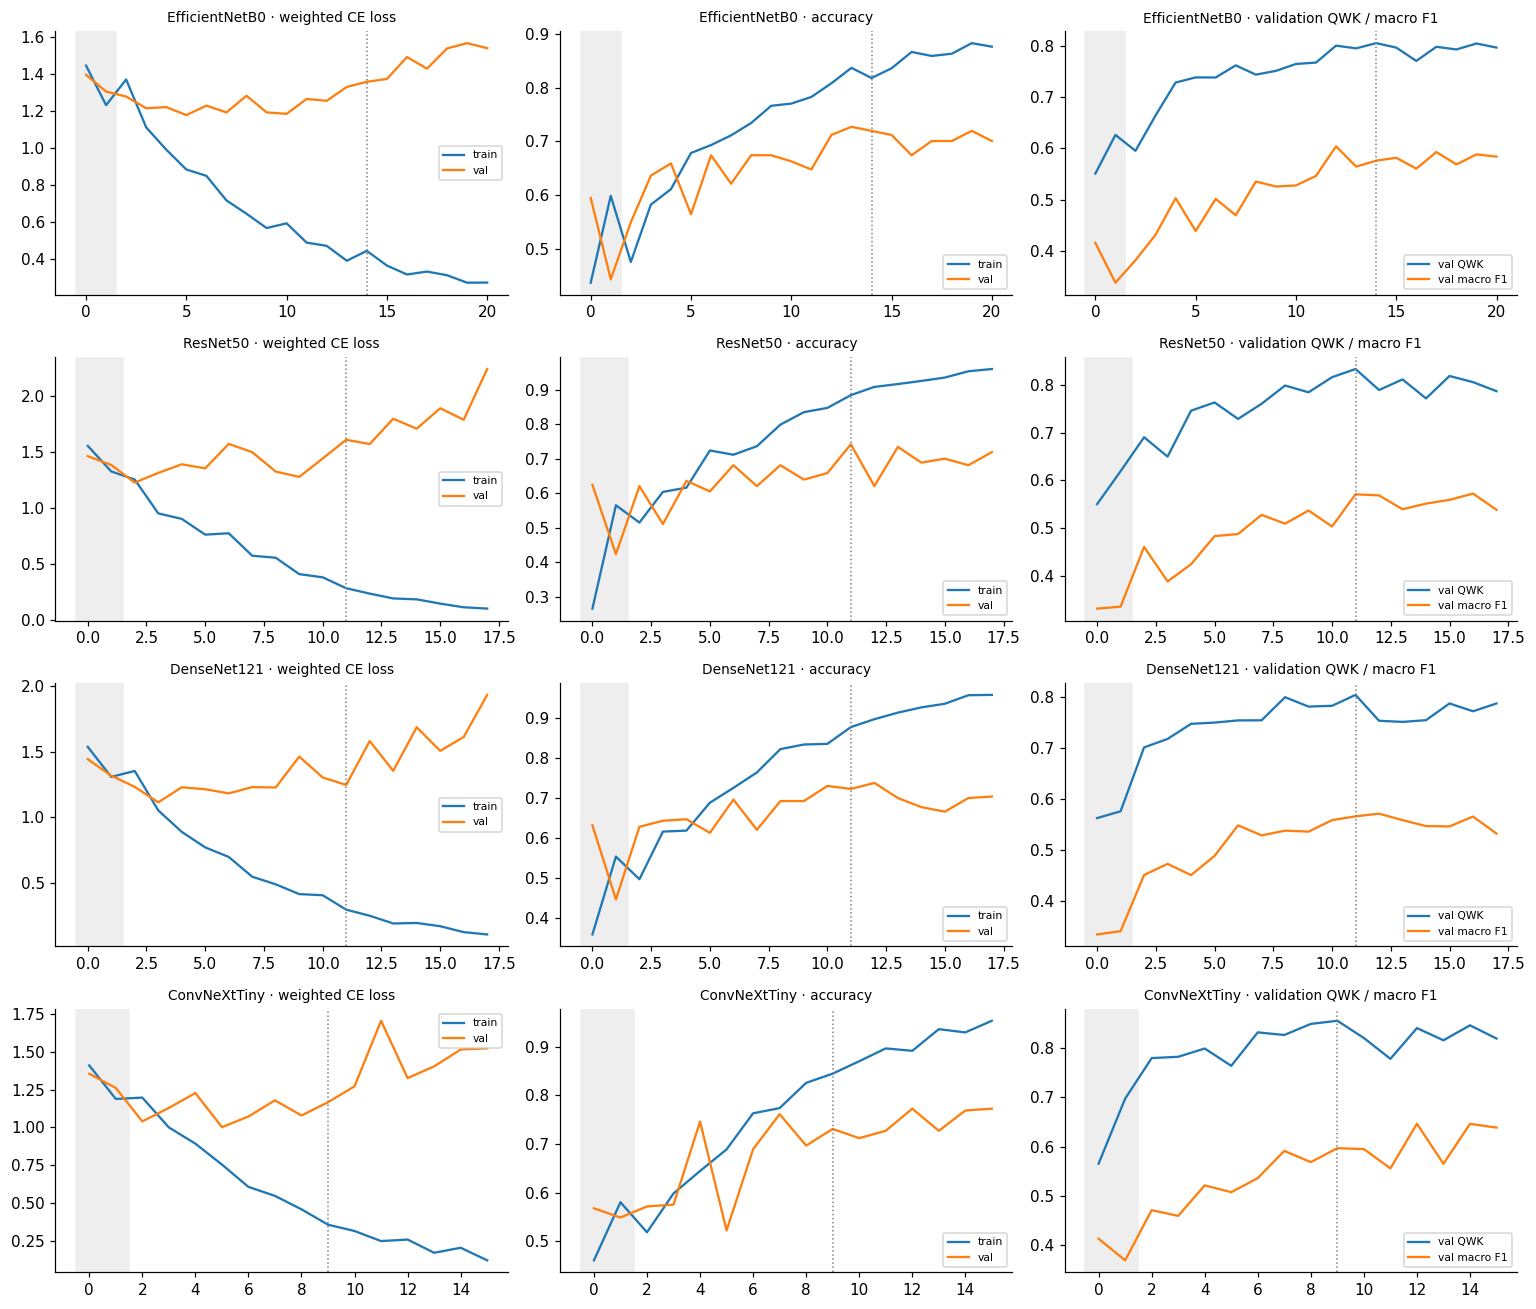

Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.


In [23]:
def plot_history(arch_runs, fname):
    fig, axes = plt.subplots(len(arch_runs), 3, figsize=(14, 3.0 * len(arch_runs)), squeeze=False)
    for r, (name, s) in enumerate(arch_runs.items()):
        h = pd.read_csv(Path(s['run_dir']) / 'history.csv')
        axes[r, 0].plot(h.epoch, h.train_loss, label='train'); axes[r, 0].plot(h.epoch, h.val_loss, label='val')
        axes[r, 1].plot(h.epoch, h.train_acc, label='train'); axes[r, 1].plot(h.epoch, h.val_acc, label='val')
        axes[r, 2].plot(h.epoch, h.val_qwk, label='val QWK'); axes[r, 2].plot(h.epoch, h.val_macro_f1, label='val macro F1')
        for a, t in zip(axes[r], ('weighted CE loss', 'accuracy', 'validation QWK / macro F1')):
            a.axvline(s['best_epoch'], color='grey', ls=':', lw=1); a.set_title(f'{name} · {t}', fontsize=9); a.legend(fontsize=7)
            a.axvspan(-0.5, PROTOCOL['warmup_frozen_epochs'] - 0.5, color='#eee')
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_history(MAIN_RUNS, 'training_curves_main.png')
print('Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.')

## 15 · Model selection on the validation set (frozen before any test evaluation)
Rule fixed in advance: highest validation QWK; ties (< 0.001) broken by validation macro F1,
then by fewer parameters. The decision is written to `selection.json` with a timestamp
**before** the test set is evaluated.

In [24]:
sel_df = pd.DataFrame(MAIN_RUNS.values())
sel_df['params'] = sel_df.architecture.map(arch_table[arch_table.attention == 'cbam'].set_index('architecture').params_total_M)
sel_df['qwk_r'] = sel_df.val_qwk.round(3)
sel_df = sel_df.sort_values(['qwk_r', 'val_macro_f1', 'params'], ascending=[False, False, True])
SELECTED_ARCH = sel_df.iloc[0].architecture
selection_file = EXP_DIR / 'selection.json'
if selection_file.exists() and not RUN_OPTIONS['force_retrain']:
    prev = json.loads(selection_file.read_text())
    assert prev['selected_architecture'] == SELECTED_ARCH, 'Selection changed since the frozen decision; investigate.'
else:
    save_json(dict(selected_architecture=SELECTED_ARCH, criterion=f'max validation {PRIMARY}; tie-break macro F1, params',
                   validation_ranking=sel_df[['architecture', 'val_qwk', 'val_macro_f1', 'val_accuracy']].to_dict('records'),
                   decided_at=time.strftime('%Y-%m-%d %H:%M:%S'), test_set_used=False), selection_file)
display(sel_df[['architecture', 'val_qwk', 'val_macro_f1', 'val_accuracy', 'params']].round(4).reset_index(drop=True))
print(f'Selected architecture for {EXPERIMENT_ID}: {SELECTED_ARCH} (validation-based)')

,architecture,val_qwk,val_macro_f1,val_accuracy,params
0,ConvNeXtTiny,0.8548,0.5967,0.7311,27.8978
1,ResNet50,0.8326,0.5710,0.7424,24.0427
2,EfficientNetB0,0.8053,0.5761,0.7197,4.2189
3,DenseNet121,0.8045,0.5659,0.7235,7.0902


Selected architecture for 03_Green_Channel: ConvNeXtTiny (validation-based)


## 16 · Held-out test evaluation
Each model's best-validation checkpoint is evaluated once on the untouched test split.
Reported: accuracy, balanced accuracy, macro precision/recall/F1, weighted F1, QWK, per-grade
precision, sensitivity (recall), specificity, F1, support and one-vs-rest ROC-AUC, expected
calibration error (15 bins), confusion matrices and the full classification report.
*Why not accuracy alone?* With ~49% of images in grade 0, a model predicting "No DR" for
everything reaches ~49% accuracy while detecting no disease; accuracy also ignores the
ordinal distance of errors. Macro metrics weight every grade equally and QWK accounts for
the severity of each misclassification.


### EfficientNetB0 (CBAM) — test set


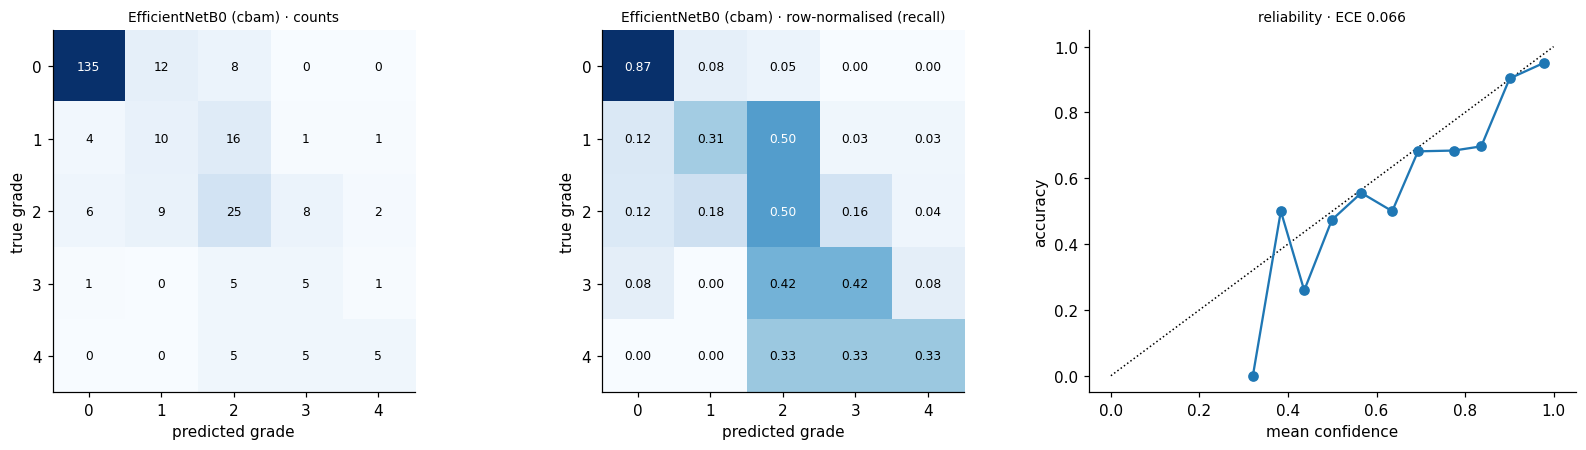

                  precision    recall  f1-score   support

           No DR     0.9247    0.8710    0.8970       155
         Mild DR     0.3226    0.3125    0.3175        32
     Moderate DR     0.4237    0.5000    0.4587        50
       Severe DR     0.2632    0.4167    0.3226        12
Proliferative DR     0.5556    0.3333    0.4167        15

        accuracy                         0.6818       264
       macro avg     0.4979    0.4867    0.4825       264
    weighted avg     0.7058    0.6818    0.6903       264


### ResNet50 (CBAM) — test set


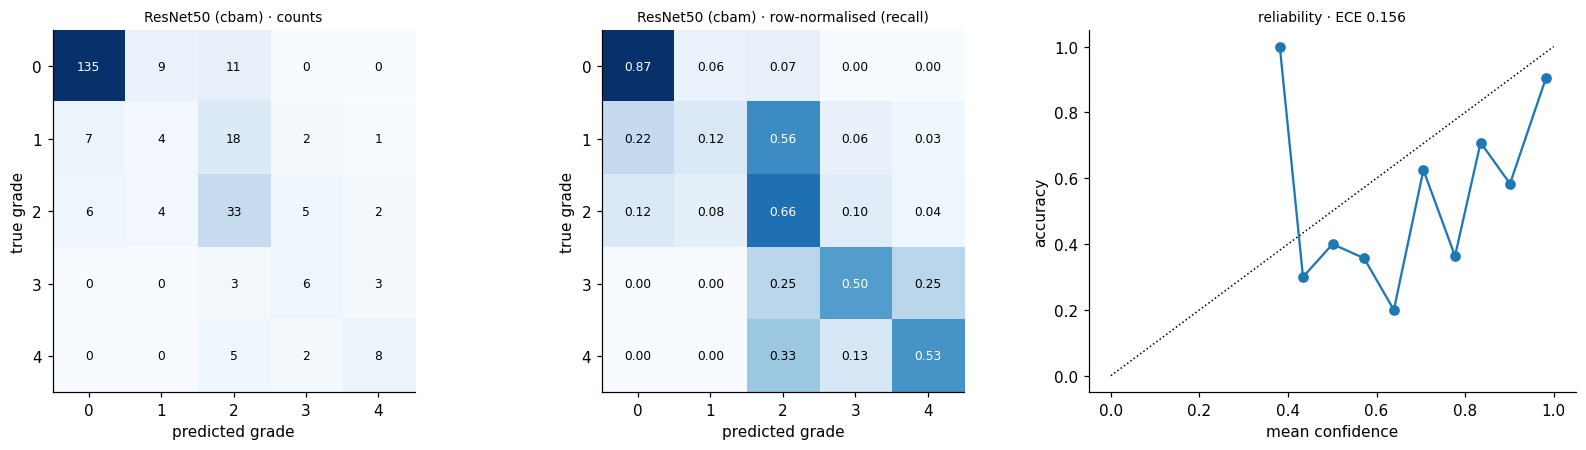

                  precision    recall  f1-score   support

           No DR     0.9122    0.8710    0.8911       155
         Mild DR     0.2353    0.1250    0.1633        32
     Moderate DR     0.4714    0.6600    0.5500        50
       Severe DR     0.4000    0.5000    0.4444        12
Proliferative DR     0.5714    0.5333    0.5517        15

        accuracy                         0.7045       264
       macro avg     0.5181    0.5379    0.5201       264
    weighted avg     0.7040    0.7045    0.6987       264


### DenseNet121 (CBAM) — test set


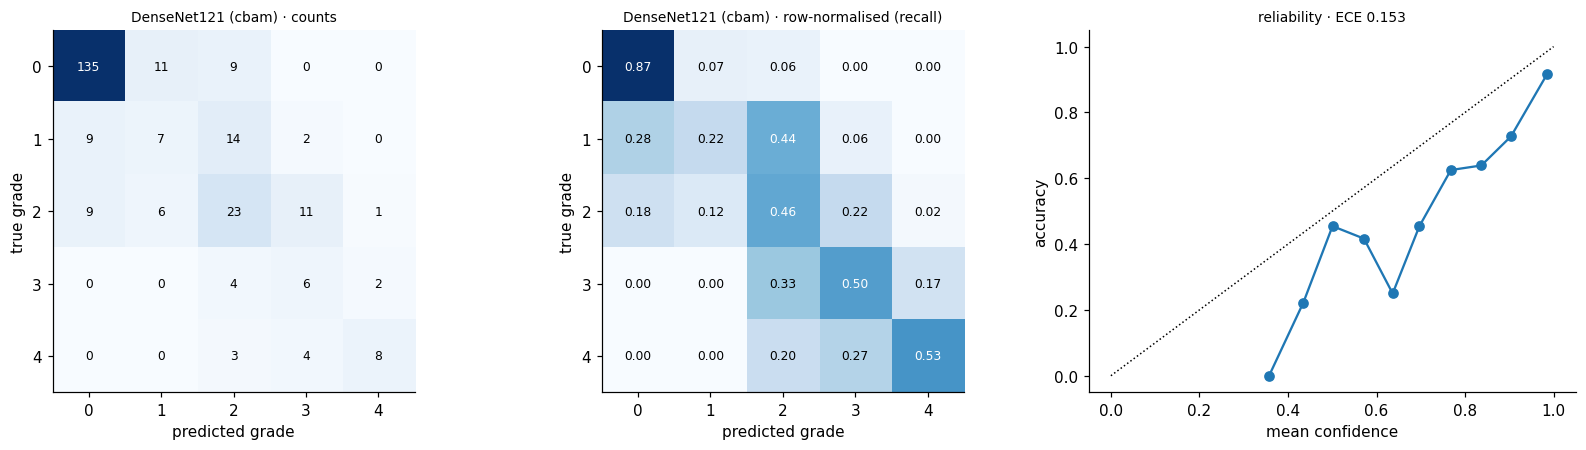

                  precision    recall  f1-score   support

           No DR     0.8824    0.8710    0.8766       155
         Mild DR     0.2917    0.2188    0.2500        32
     Moderate DR     0.4340    0.4600    0.4466        50
       Severe DR     0.2609    0.5000    0.3429        12
Proliferative DR     0.7273    0.5333    0.6154        15

        accuracy                         0.6780       264
       macro avg     0.5192    0.5166    0.5063       264
    weighted avg     0.6888    0.6780    0.6801       264


### ConvNeXtTiny (CBAM) — test set


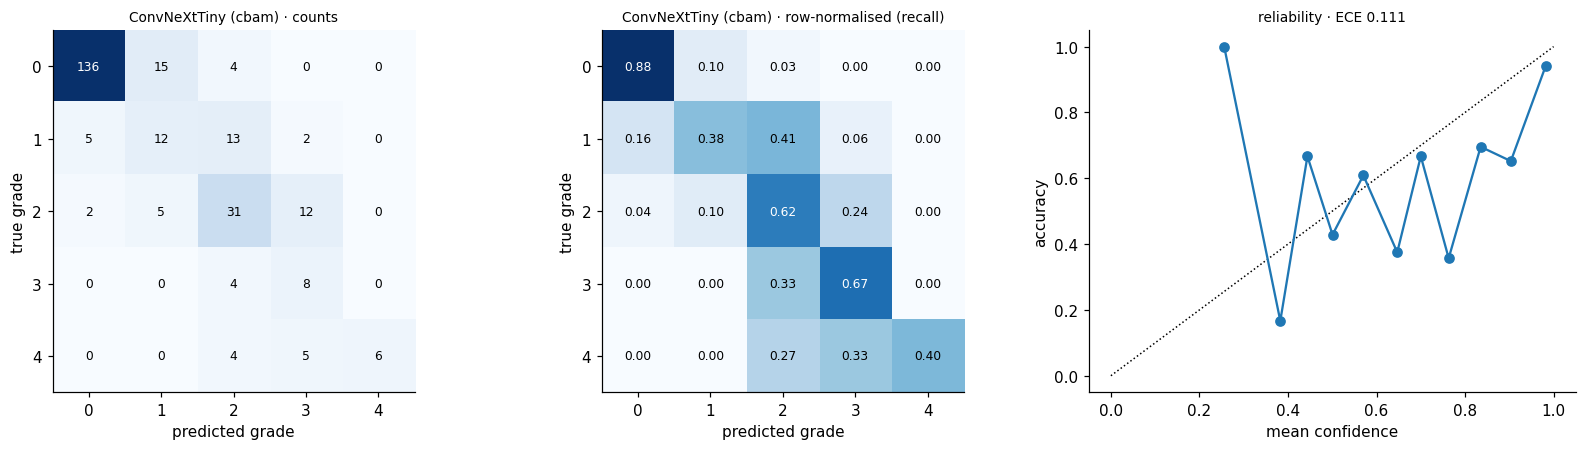

                  precision    recall  f1-score   support

           No DR     0.9510    0.8774    0.9128       155
         Mild DR     0.3750    0.3750    0.3750        32
     Moderate DR     0.5536    0.6200    0.5849        50
       Severe DR     0.2963    0.6667    0.4103        12
Proliferative DR     1.0000    0.4000    0.5714        15

        accuracy                         0.7311       264
       macro avg     0.6352    0.5878    0.5709       264
    weighted avg     0.7790    0.7311    0.7432       264



**Aggregate test metrics (all four architectures, CBAM, seed 42)**

,selected,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,qwk,roc_auc_ovr_macro,ece
EfficientNetB0,False,0.6818,0.4867,0.4979,0.4867,0.4825,0.6903,0.7769,0.8461,0.0661
ResNet50,False,0.7045,0.5379,0.5181,0.5379,0.5201,0.6987,0.7925,0.8511,0.1561
DenseNet121,False,0.6780,0.5166,0.5192,0.5166,0.5063,0.6801,0.7985,0.8755,0.1527
ConvNeXtTiny,True,0.7311,0.5878,0.6352,0.5878,0.5709,0.7432,0.8564,0.9017,0.1106


**Per-grade test metrics**

sensitivity                                               f1                                    
architecture       ConvNeXtTiny DenseNet121 EfficientNetB0 ResNet50 ConvNeXtTiny DenseNet121 EfficientNetB0 ResNet50
grade                                                                                                               
0 No DR                   0.877       0.871          0.871    0.871        0.913       0.877          0.897    0.891
1 Mild DR                 0.375       0.219          0.312    0.125        0.375       0.250          0.317    0.163
2 Moderate DR             0.620       0.460          0.500    0.660        0.585       0.447          0.459    0.550
3 Severe DR               0.667       0.500          0.417    0.500        0.410       0.343          0.323    0.444
4 Proliferative DR        0.400       0.533          0.333    0.533        0.571       0.615          0.417    0.552

In [25]:
def evaluate_run(summary):
    rdir = Path(summary['run_dir'])
    model, cfg = load_dr_model(rdir, device=DEVICE)
    prob, y, _ = predict(model, make_loader('test', False, 0))
    met = MT.compute_metrics(y, prob, GRADE_NAMES)
    pred_df = pd.DataFrame({'image_id': manifest.image_id.values[IDX['test']], 'label': y, 'pred': prob.argmax(1),
                            'group': GROUPS_TEST, **{f'p{k}': prob[:, k] for k in range(5)}})
    pred_df.to_csv(rdir / 'test_predictions.csv', index=False)
    save_json(met, rdir / 'test_metrics.json')
    (rdir / 'classification_report.txt').write_text(met['classification_report'])
    cm = np.array(met['confusion_matrix'])
    pd.DataFrame(cm, index=[f'true {k}' for k in range(5)], columns=[f'pred {k}' for k in range(5)]).to_csv(rdir / 'confusion_matrix.csv')
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, mat, title, fmt in ((axes[0], cm, 'counts', 'd'),
                                (axes[1], cm / cm.sum(1, keepdims=True).clip(1), 'row-normalised (recall)', '.2f')):
        ax.imshow(mat, cmap='Blues')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, format(mat[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if mat[i, j] > mat.max() / 2 else 'black')
        ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xlabel('predicted grade'); ax.set_ylabel('true grade')
        ax.set_title(f"{summary['architecture']} ({summary['attention']}) · {title}", fontsize=9)
    rel = np.array(met['reliability']) if met['reliability'] else np.zeros((0, 4))
    axes[2].plot([0, 1], [0, 1], 'k:', lw=1)
    if len(rel): axes[2].plot(rel[:, 1], rel[:, 2], 'o-')
    axes[2].set_xlabel('mean confidence'); axes[2].set_ylabel('accuracy'); axes[2].set_title(f"reliability · ECE {met['ece']:.3f}", fontsize=9)
    plt.tight_layout(); plt.savefig(rdir / 'confusion_matrix.png', bbox_inches='tight'); plt.show()
    del model
    return met, pred_df

TEST = {}
for arch in PROTOCOL['architectures']:
    print(f'\n### {arch} (CBAM) — test set')
    TEST[arch] = evaluate_run(MAIN_RUNS[arch])
    print(TEST[arch][0]['classification_report'])

agg_cols = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'qwk', 'roc_auc_ovr_macro', 'ece']
agg = pd.DataFrame({a: {c: TEST[a][0][c] for c in agg_cols} for a in TEST}).T
agg.insert(0, 'selected', [a == SELECTED_ARCH for a in agg.index])
display(Markdown('**Aggregate test metrics (all four architectures, CBAM, seed 42)**')); display(agg.round(4))
per_rows = []
for a in TEST:
    for k, v in TEST[a][0]['per_class'].items():
        per_rows.append(dict(architecture=a, grade=f"{k} {v['grade']}", sensitivity=v['recall_sensitivity'],
                             specificity=v['specificity'], precision=v['precision'], f1=v['f1'], auc=v['roc_auc_ovr'], support=v['support']))
per_df = pd.DataFrame(per_rows)
display(Markdown('**Per-grade test metrics**')); display(per_df.pivot(index='grade', columns='architecture', values=['sensitivity', 'f1']).round(3))
agg.to_csv(EXP_DIR / 'test_metrics_main.csv'); per_df.to_csv(EXP_DIR / 'test_per_class_main.csv', index=False)

## 17 · Multiple seeds and controlled attention ablation
For the **validation-selected** architecture only (compute budget), the CBAM model is retrained
with additional seeds and the identical architecture **without CBAM** is trained with the same
seeds, data, split, augmentation and schedule. Seed s controls head/CBAM initialisation,
data order and augmentation; pretrained backbone weights are the same file for every run.
Because only the selected architecture is ablated, the attention conclusion is limited to that
architecture (disclosed limitation). Set `RUN_OPTIONS['run_ablation']=False` to skip.


=== ablation | ConvNeXtTiny | none | seed 42 ===
  ep00 F loss 1.416/1.391 acc 0.439/0.576 vF1 0.390 vQWK 0.554  *best  [0.1 min]
  ep01 F loss 1.205/1.297 acc 0.589/0.606 vF1 0.360 vQWK 0.663  *best  [0.2 min]
  ep02   loss 1.191/1.040 acc 0.546/0.670 vF1 0.519 vQWK 0.770  *best  [0.4 min]
  ep03   loss 0.933/1.058 acc 0.637/0.610 vF1 0.492 vQWK 0.757  [0.6 min]
  ep04   loss 0.860/1.052 acc 0.666/0.754 vF1 0.550 vQWK 0.823  *best  [0.8 min]
  ep05   loss 0.703/1.008 acc 0.736/0.617 vF1 0.553 vQWK 0.811  [1.0 min]
  ep06   loss 0.574/1.127 acc 0.772/0.686 vF1 0.548 vQWK 0.836  *best  [1.1 min]
  ep07   loss 0.498/1.073 acc 0.804/0.750 vF1 0.607 vQWK 0.852  *best  [1.4 min]
  ep08   loss 0.373/1.188 acc 0.849/0.663 vF1 0.530 vQWK 0.850  [1.6 min]
  ep09   loss 0.355/1.215 acc 0.850/0.750 vF1 0.594 vQWK 0.858  *best  [1.7 min]
  ep10   loss 0.284/1.266 acc 0.887/0.720 vF1 0.590 vQWK 0.814  [1.9 min]
  ep11   loss 0.244/1.514 acc 0.900/0.773 vF1 0.613 vQWK 0.822  [2.1 min]
  ep12   loss

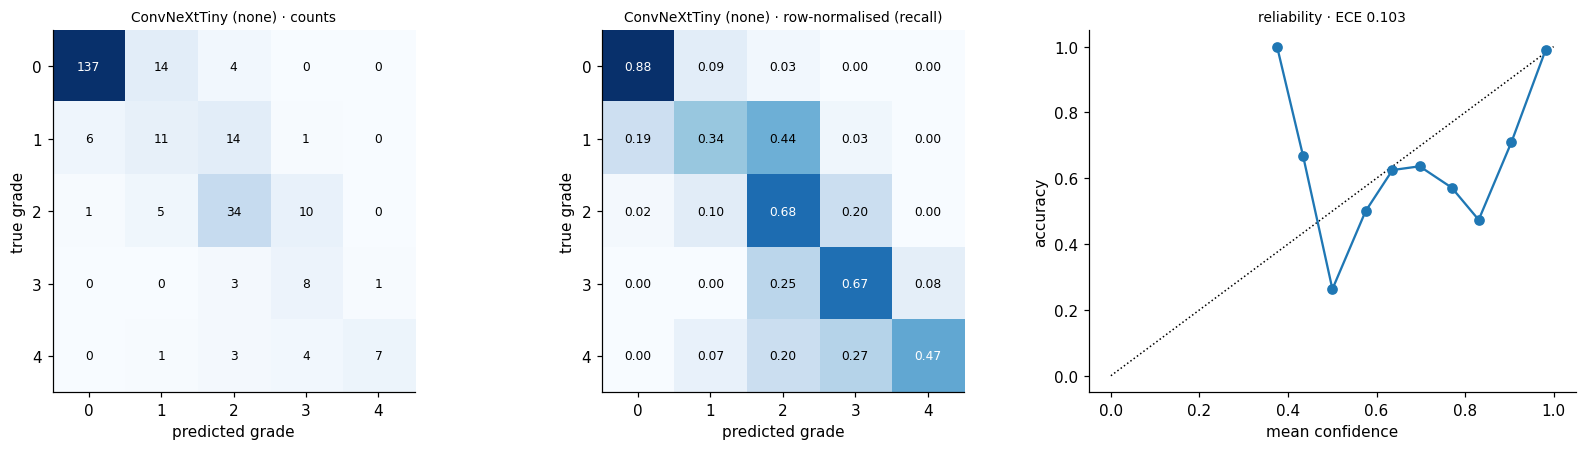


=== ablation | ConvNeXtTiny | cbam | seed 43 ===
  ep00 F loss 1.427/1.412 acc 0.385/0.549 vF1 0.312 vQWK 0.535  *best  [0.1 min]
  ep01 F loss 1.172/1.244 acc 0.565/0.693 vF1 0.519 vQWK 0.698  *best  [0.3 min]
  ep02   loss 1.241/1.234 acc 0.531/0.580 vF1 0.368 vQWK 0.702  *best  [0.5 min]
  ep03   loss 1.003/1.279 acc 0.637/0.727 vF1 0.512 vQWK 0.754  *best  [0.7 min]
  ep04   loss 0.879/1.220 acc 0.674/0.701 vF1 0.488 vQWK 0.756  *best  [0.9 min]
  ep05   loss 0.740/1.221 acc 0.723/0.697 vF1 0.518 vQWK 0.742  [1.1 min]
  ep06   loss 0.690/1.019 acc 0.730/0.697 vF1 0.571 vQWK 0.844  *best  [1.3 min]
  ep07   loss 0.533/0.990 acc 0.789/0.655 vF1 0.599 vQWK 0.840  [1.4 min]
  ep08   loss 0.529/1.088 acc 0.805/0.629 vF1 0.537 vQWK 0.809  [1.6 min]
  ep09   loss 0.376/1.337 acc 0.841/0.742 vF1 0.597 vQWK 0.823  [1.8 min]
  ep10   loss 0.324/1.122 acc 0.852/0.678 vF1 0.561 vQWK 0.848  *best  [2.0 min]
  ep11   loss 0.283/1.222 acc 0.893/0.716 vF1 0.583 vQWK 0.843  [2.2 min]
  ep12   loss

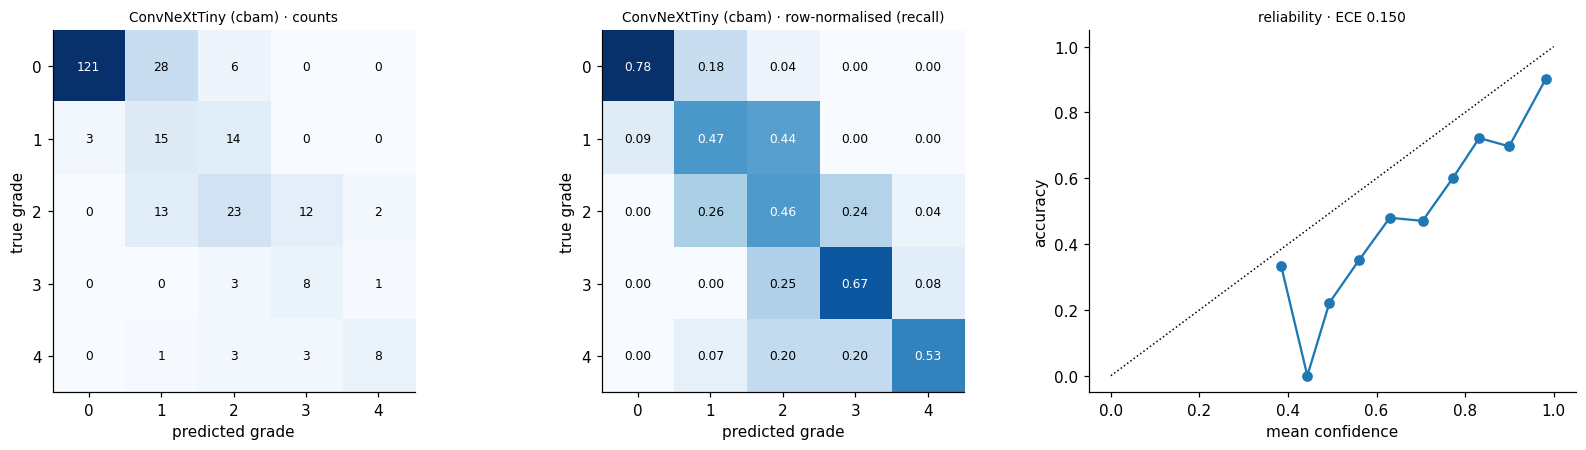


=== ablation | ConvNeXtTiny | none | seed 43 ===
  ep00 F loss 1.451/1.385 acc 0.410/0.595 vF1 0.305 vQWK 0.635  *best  [0.1 min]
  ep01 F loss 1.211/1.280 acc 0.565/0.625 vF1 0.464 vQWK 0.698  *best  [0.2 min]
  ep02   loss 1.293/1.260 acc 0.519/0.519 vF1 0.383 vQWK 0.692  [0.4 min]
  ep03   loss 0.998/1.068 acc 0.633/0.705 vF1 0.503 vQWK 0.787  *best  [0.6 min]
  ep04   loss 0.834/1.168 acc 0.682/0.727 vF1 0.520 vQWK 0.760  [0.8 min]
  ep05   loss 0.759/1.190 acc 0.715/0.693 vF1 0.513 vQWK 0.773  [1.1 min]
  ep06   loss 0.695/0.920 acc 0.738/0.693 vF1 0.599 vQWK 0.872  *best  [1.2 min]
  ep07   loss 0.530/0.984 acc 0.799/0.591 vF1 0.540 vQWK 0.812  [1.5 min]
  ep08   loss 0.517/0.995 acc 0.789/0.705 vF1 0.620 vQWK 0.861  [1.7 min]
  ep09   loss 0.342/1.379 acc 0.854/0.746 vF1 0.578 vQWK 0.797  [1.9 min]
  ep10   loss 0.287/1.116 acc 0.871/0.739 vF1 0.595 vQWK 0.847  [2.1 min]
  ep11   loss 0.244/1.113 acc 0.900/0.686 vF1 0.633 vQWK 0.843  [2.3 min]
  ep12   loss 0.202/1.386 acc 0.91

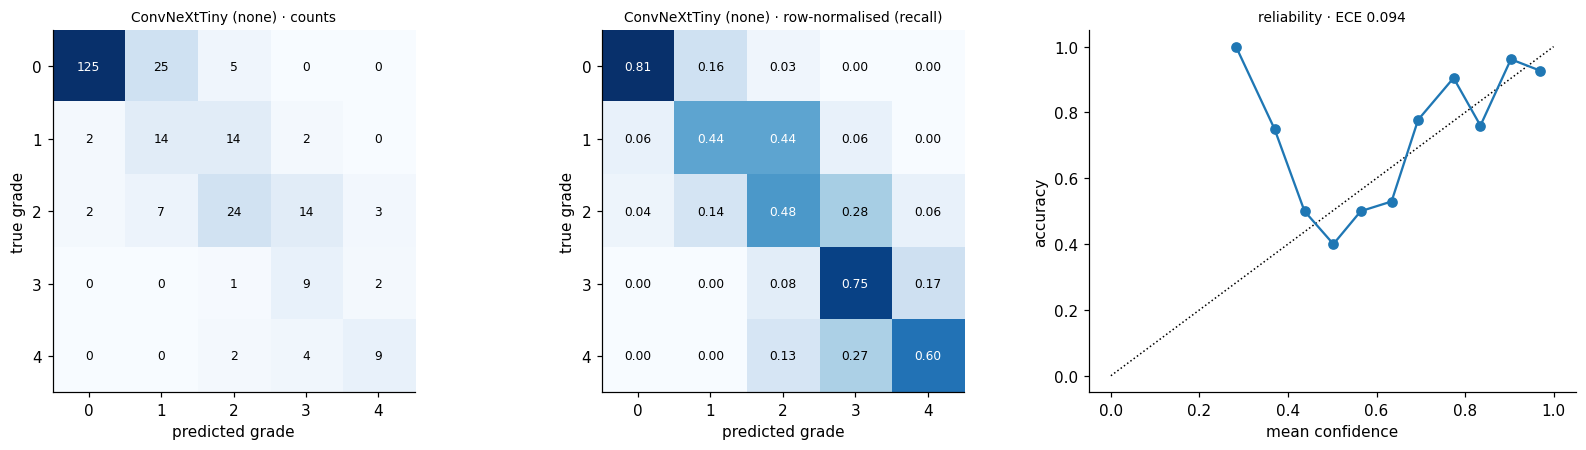


=== ablation | ConvNeXtTiny | cbam | seed 44 ===
  ep00 F loss 1.425/1.338 acc 0.424/0.511 vF1 0.391 vQWK 0.574  *best  [0.1 min]
  ep01 F loss 1.180/1.258 acc 0.557/0.602 vF1 0.399 vQWK 0.674  *best  [0.4 min]
  ep02   loss 1.259/1.217 acc 0.532/0.648 vF1 0.443 vQWK 0.746  *best  [0.6 min]
  ep03   loss 0.990/1.053 acc 0.634/0.716 vF1 0.557 vQWK 0.771  *best  [0.8 min]
  ep04   loss 0.815/1.061 acc 0.690/0.731 vF1 0.584 vQWK 0.824  *best  [1.0 min]
  ep05   loss 0.694/1.022 acc 0.735/0.777 vF1 0.652 vQWK 0.822  [1.2 min]
  ep06   loss 0.668/0.997 acc 0.713/0.682 vF1 0.583 vQWK 0.800  [1.4 min]
  ep07   loss 0.523/1.157 acc 0.803/0.769 vF1 0.624 vQWK 0.806  [1.5 min]
  ep08   loss 0.463/1.263 acc 0.827/0.716 vF1 0.619 vQWK 0.825  *best  [1.7 min]
  ep09   loss 0.439/1.132 acc 0.808/0.705 vF1 0.600 vQWK 0.825  [1.9 min]
  ep10   loss 0.300/1.265 acc 0.873/0.640 vF1 0.590 vQWK 0.799  [2.1 min]
  ep11   loss 0.285/1.420 acc 0.873/0.742 vF1 0.627 vQWK 0.823  [2.3 min]
  ep12   loss 0.220/

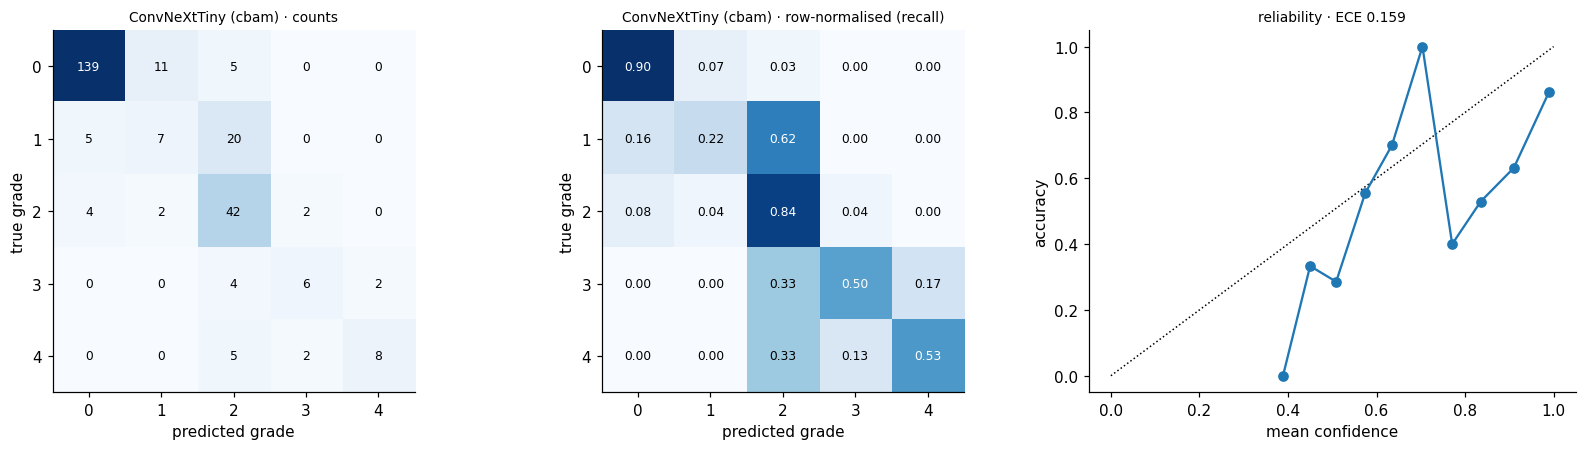


=== ablation | ConvNeXtTiny | none | seed 44 ===
  ep00 F loss 1.443/1.352 acc 0.423/0.625 vF1 0.374 vQWK 0.685  *best  [0.1 min]
  ep01 F loss 1.222/1.284 acc 0.542/0.625 vF1 0.387 vQWK 0.693  *best  [0.2 min]
  ep02   loss 1.185/1.216 acc 0.537/0.633 vF1 0.437 vQWK 0.765  *best  [0.4 min]
  ep03   loss 0.949/1.095 acc 0.639/0.553 vF1 0.456 vQWK 0.776  *best  [0.6 min]
  ep04   loss 0.824/1.097 acc 0.675/0.723 vF1 0.552 vQWK 0.783  *best  [0.8 min]
  ep05   loss 0.712/1.060 acc 0.744/0.758 vF1 0.593 vQWK 0.819  *best  [1.0 min]
  ep06   loss 0.644/1.164 acc 0.739/0.572 vF1 0.495 vQWK 0.761  [1.1 min]
  ep07   loss 0.514/1.236 acc 0.799/0.739 vF1 0.583 vQWK 0.812  [1.3 min]
  ep08   loss 0.376/1.177 acc 0.860/0.693 vF1 0.583 vQWK 0.829  *best  [1.5 min]
  ep09   loss 0.386/1.201 acc 0.839/0.712 vF1 0.638 vQWK 0.809  [1.9 min]
  ep10   loss 0.271/1.262 acc 0.892/0.621 vF1 0.579 vQWK 0.800  [2.1 min]
  ep11   loss 0.252/1.534 acc 0.900/0.742 vF1 0.555 vQWK 0.802  [2.2 min]
  ep12   loss

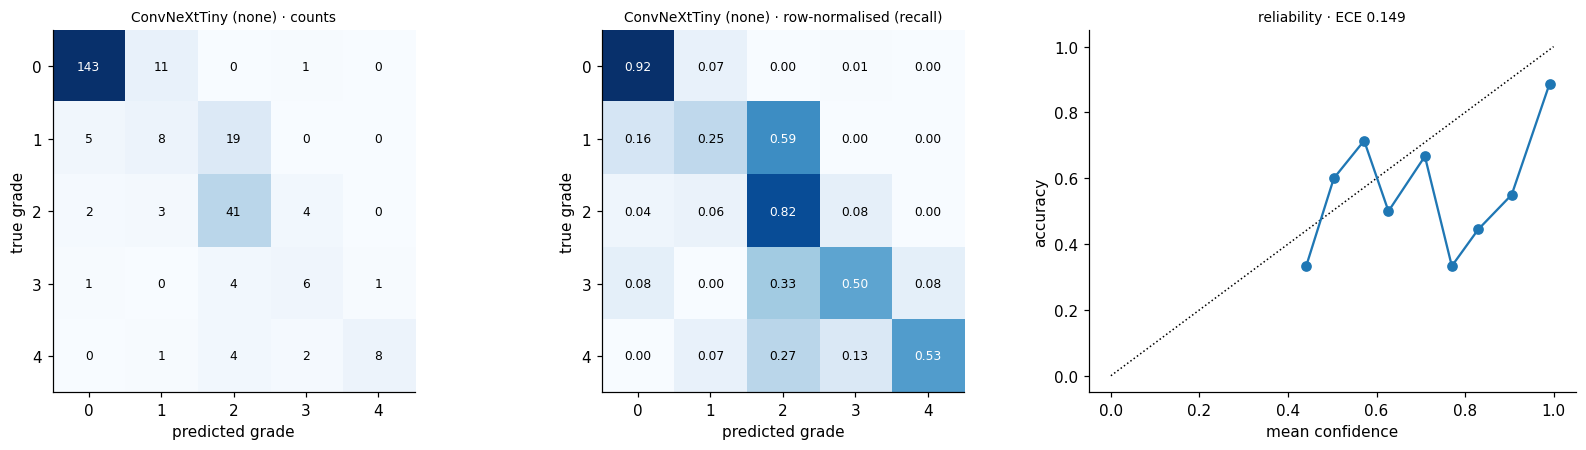

,attention,seed,val_qwk,val_macro_f1,test_qwk,test_macro_f1,test_accuracy,test_balanced_accuracy,best_epoch
0,cbam,42,0.8548,0.5967,0.8564,0.5709,0.7311,0.5878,9
2,cbam,43,0.8481,0.5610,0.8274,0.5483,0.6629,0.5819,10
4,cbam,44,0.8651,0.6200,0.8587,0.6078,0.7652,0.5978,15
1,none,42,0.8584,0.5935,0.8639,0.5922,0.7462,0.6082,9
3,none,43,0.8717,0.5992,0.8456,0.5598,0.6856,0.6148,6
5,none,44,0.8477,0.6010,0.8634,0.6134,0.7803,0.6052,15


**Mean ± SD across 3 seeds (ConvNeXtTiny)**

val_qwk         val_macro_f1         test_qwk         test_macro_f1        test_accuracy        
             mean     std         mean     std     mean     std          mean    std          mean     std
attention                                                                                                 
cbam       0.8560  0.0085       0.5925  0.0297   0.8475  0.0174        0.5757  0.030        0.7197  0.0521
none       0.8593  0.0120       0.5979  0.0039   0.8576  0.0104        0.5885  0.027        0.7374  0.0480

In [26]:
ABL = {}
if RUN_OPTIONS['run_ablation']:
    for seed in PROTOCOL['ablation_seeds']:
        for att in ('cbam', 'none'):
            if att == 'cbam' and seed == PROTOCOL['seed_main']:
                ABL[(att, seed)] = (MAIN_RUNS[SELECTED_ARCH], TEST[SELECTED_ARCH]); continue
            print(f'\n=== ablation | {SELECTED_ARCH} | {att} | seed {seed} ===')
            s = train_run(SELECTED_ARCH, att, seed)
            ABL[(att, seed)] = (s, evaluate_run(s))
    abl_rows = [dict(attention=att, seed=seed, val_qwk=s['val_qwk'], val_macro_f1=s['val_macro_f1'],
                     test_qwk=m[0]['qwk'], test_macro_f1=m[0]['macro_f1'], test_accuracy=m[0]['accuracy'],
                     test_balanced_accuracy=m[0]['balanced_accuracy'], best_epoch=s['best_epoch'])
                for (att, seed), (s, m) in ABL.items()]
    abl_df = pd.DataFrame(abl_rows).sort_values(['attention', 'seed'])
    display(abl_df.round(4))
    abl_summary = abl_df.groupby('attention')[['val_qwk', 'val_macro_f1', 'test_qwk', 'test_macro_f1', 'test_accuracy']].agg(['mean', 'std'])
    display(Markdown(f'**Mean ± SD across {len(PROTOCOL["ablation_seeds"])} seeds ({SELECTED_ARCH})**')); display(abl_summary.round(4))
    abl_df.to_csv(EXP_DIR / 'attention_ablation_runs.csv', index=False)
else:
    abl_df = None
    print('Ablation skipped by configuration (limitation: no seed variance / attention evidence).')

## 18 · Statistical analysis
* **95% confidence intervals:** percentile bootstrap (2,000 resamples) over test images
  (resampling duplicate/patient groups when present).
* **Architecture comparisons:** two-sided paired permutation tests (5,000 swaps) of the
  selected architecture against each other architecture on the same test images, for QWK and
  macro F1, Holm-corrected within each metric. These are **exploratory** (the selected model
  was chosen on validation data, and four models share one test set).
* **Attention ablation:** for each seed, a paired permutation test and paired-bootstrap CI of
  Δ = CBAM − NoAttn. With only a few seeds, consistency of the sign across seeds is reported
  rather than claiming significance.

In [27]:
B, NP, ALPHA = PROTOCOL['n_bootstrap'], PROTOCOL['n_permutations'], PROTOCOL['alpha']
ci_rows = []
for a, (met, pdf) in TEST.items():
    ci = MT.bootstrap_ci(pdf.label.values, pdf.pred.values, groups=pdf.group.values, n_boot=B, alpha=ALPHA, seed=1)
    for k, v in ci.items():
        ci_rows.append(dict(architecture=a, metric=k, estimate=v['estimate'], ci_low=v['ci_low'], ci_high=v['ci_high']))
ci_df = pd.DataFrame(ci_rows)
ci_df['formatted'] = ci_df.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
display(Markdown('**Test metrics with 95% bootstrap CIs**'))
display(ci_df.pivot(index='architecture', columns='metric', values='formatted'))
ci_df.to_csv(EXP_DIR / 'test_bootstrap_ci_main.csv', index=False)

ref = TEST[SELECTED_ARCH][1]
cmp_rows = []
for metric in ('qwk', 'macro_f1'):
    rows = []
    for a in TEST:
        if a == SELECTED_ARCH: continue
        other = TEST[a][1]
        assert (other.image_id.values == ref.image_id.values).all()
        pt = MT.paired_permutation_test(ref.label.values, ref.pred.values, other.pred.values, metric, ref.group.values, NP, seed=2)
        bd = MT.paired_bootstrap_diff(ref.label.values, ref.pred.values, other.pred.values, metric, ref.group.values, B, ALPHA, seed=3)
        rows.append(dict(metric=metric, comparison=f'{SELECTED_ARCH} − {a}', diff=pt['diff'], ci_low=bd['ci_low'], ci_high=bd['ci_high'], p_raw=pt['p_value']))
    adj = MT.holm_correction([r['p_raw'] for r in rows])
    for r, p in zip(rows, adj): r['p_holm'] = p
    cmp_rows += rows
cmp_df = pd.DataFrame(cmp_rows)
display(Markdown('**Exploratory paired comparisons on the test set (selected vs others)**')); display(cmp_df.round(4))
cmp_df.to_csv(EXP_DIR / 'architecture_comparisons.csv', index=False)

abl_tests = None
if abl_df is not None:
    rows = []
    for seed in PROTOCOL['ablation_seeds']:
        pa, pb = ABL[('cbam', seed)][1][1], ABL[('none', seed)][1][1]
        for metric in ('qwk', 'macro_f1'):
            pt = MT.paired_permutation_test(pa.label.values, pa.pred.values, pb.pred.values, metric, pa.group.values, NP, seed=4)
            bd = MT.paired_bootstrap_diff(pa.label.values, pa.pred.values, pb.pred.values, metric, pa.group.values, B, ALPHA, seed=5)
            rows.append(dict(seed=seed, metric=metric, diff_cbam_minus_noattn=pt['diff'], ci_low=bd['ci_low'], ci_high=bd['ci_high'], p_value=pt['p_value']))
    abl_tests = pd.DataFrame(rows)
    display(Markdown('**Attention ablation: Δ = CBAM − NoAttn per seed (test set)**')); display(abl_tests.round(4))
    for metric in ('qwk', 'macro_f1'):
        d = abl_tests[abl_tests.metric == metric].diff_cbam_minus_noattn
        print(f"{metric}: mean Δ {d.mean():+.4f} (SD {d.std():.4f}); positive in {(d > 0).sum()}/{len(d)} seeds")
    vd = abl_df.pivot(index='seed', columns='attention', values='val_qwk')
    print(f"validation QWK Δ per seed: {(vd['cbam'] - vd['none']).round(4).to_dict()}")
    abl_tests.to_csv(EXP_DIR / 'attention_ablation_tests.csv', index=False)

**Test metrics with 95% bootstrap CIs**

metric,accuracy,balanced_accuracy,macro_f1,qwk
architecture,,,,
ConvNeXtTiny,"0.731 [0.678, 0.784]","0.588 [0.497, 0.677]","0.571 [0.477, 0.651]","0.856 [0.813, 0.893]"
DenseNet121,"0.678 [0.621, 0.731]","0.517 [0.428, 0.602]","0.506 [0.423, 0.579]","0.799 [0.737, 0.848]"
EfficientNetB0,"0.682 [0.625, 0.739]","0.487 [0.402, 0.580]","0.482 [0.396, 0.564]","0.777 [0.714, 0.833]"
ResNet50,"0.705 [0.652, 0.754]","0.538 [0.450, 0.624]","0.520 [0.430, 0.596]","0.793 [0.731, 0.845]"


**Exploratory paired comparisons on the test set (selected vs others)**

,metric,comparison,diff,ci_low,ci_high,p_raw,p_holm
0,qwk,ConvNeXtTiny − EfficientNetB0,0.0795,0.0330,0.1348,0.0008,0.0024
1,qwk,ConvNeXtTiny − ResNet50,0.0639,0.0201,0.1159,0.0078,0.0156
2,qwk,ConvNeXtTiny − DenseNet121,0.0578,0.0140,0.1064,0.0152,0.0156
3,macro_f1,ConvNeXtTiny − EfficientNetB0,0.0884,0.0115,0.1659,0.0256,0.0768
4,macro_f1,ConvNeXtTiny − ResNet50,0.0508,-0.0383,0.1388,0.2855,0.3051
5,macro_f1,ConvNeXtTiny − DenseNet121,0.0646,-0.0239,0.1603,0.1526,0.3051


**Attention ablation: Δ = CBAM − NoAttn per seed (test set)**

,seed,metric,diff_cbam_minus_noattn,ci_low,ci_high,p_value
0,42,qwk,-0.0076,-0.0352,0.0212,0.6133
1,42,macro_f1,-0.0213,-0.0817,0.0415,0.4913
2,43,qwk,-0.0182,-0.0564,0.0178,0.3735
3,43,macro_f1,-0.0115,-0.0801,0.0517,0.7273
4,44,qwk,-0.0047,-0.0459,0.0403,0.8332
5,44,macro_f1,-0.0057,-0.0719,0.0625,0.8628


qwk: mean Δ -0.0102 (SD 0.0071); positive in 0/3 seeds
macro_f1: mean Δ -0.0128 (SD 0.0079); positive in 0/3 seeds
validation QWK Δ per seed: {42: -0.0036, 43: -0.0236, 44: 0.0174}


## 19 · Efficiency measurements
Trainable parameters, checkpoint size, wall-clock training time (to the end of early stopping),
per-image inference latency (batch 1, after warm-up) and batch throughput on the current device.

In [28]:
def measure_latency(model, bs=1, iters=30, warm=10):
    x = torch.randn(bs, 3, IMG, IMG, device=DEVICE)
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        for _ in range(warm): model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(iters): model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t) / iters

eff_rows = []
for arch in PROTOCOL['architectures']:
    s = MAIN_RUNS[arch]
    model, _ = load_dr_model(s['run_dir'], device=DEVICE)
    n_iter = 5 if SMOKE_TEST else 30
    lat1 = measure_latency(model, 1, n_iter); latb = measure_latency(model, 32, max(3, n_iter // 3))
    eff_rows.append(dict(architecture=arch, params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                         trainable_params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                         checkpoint_MB=(Path(s['run_dir']) / 'best_model.pt').stat().st_size / 1e6,
                         train_minutes=s['train_seconds'] / 60, epochs=s['epochs_run'],
                         latency_ms_bs1=1000 * lat1, throughput_img_s_bs32=32 / latb, device=ENV['gpu'] or 'cpu',
                         test_qwk=TEST[arch][0]['qwk'], test_macro_f1=TEST[arch][0]['macro_f1']))
    del model
eff_df = pd.DataFrame(eff_rows)
display(eff_df.round(3)); eff_df.to_csv(EXP_DIR / 'efficiency.csv', index=False)
print('All parameters are trainable during full fine-tuning (backbone frozen only for the 2 warm-up epochs).')

,architecture,params_M,trainable_params_M,checkpoint_MB,train_minutes,epochs,latency_ms_bs1,throughput_img_s_bs32,device,test_qwk,test_macro_f1
0,EfficientNetB0,4.219,4.219,17.176,3.071,21,9.760,1201.229,Tesla T4,0.777,0.482
1,ResNet50,24.043,24.043,96.493,3.239,18,7.315,710.189,Tesla T4,0.793,0.520
2,DenseNet121,7.090,7.090,28.972,3.072,18,17.806,572.770,Tesla T4,0.799,0.506
3,ConvNeXtTiny,27.898,27.898,111.660,3.058,16,9.693,578.805,Tesla T4,0.856,0.571


All parameters are trainable during full fine-tuning (backbone frozen only for the 2 warm-up epochs).


## 20 · Export of inference artifacts and deployment round-trip check
Each run folder now contains `best_model.pt` (state_dict), `model_config.json` (everything needed
to rebuild the model and its preprocessing), metrics, predictions, history, confusion matrix and
a README. The `dr_lib` package is copied to `DR_Grading_Research/inference_package/` for use in a
Python backend (Django/FastAPI) that serves the React application. As a reproducibility check, a
few **raw** test images are re-graded through the deployment path (decode → standardise →
preprocess → model) and compared with the evaluation predictions.

In [29]:
PKG = OUTPUT_ROOT / 'inference_package'
(PKG / 'dr_lib').mkdir(parents=True, exist_ok=True)
for p in LIB_DIR.glob('*.py'):
    shutil.copy(p, PKG / 'dr_lib' / p.name)
(PKG / 'example_backend.py').write_text('''"""Minimal FastAPI example: POST an image, receive grade + probabilities.
pip install fastapi uvicorn python-multipart torch torchvision opencv-python-headless PyWavelets
uvicorn example_backend:app --host 0.0.0.0 --port 8000
"""
import os
from fastapi import FastAPI, File, UploadFile
from dr_lib.inference import load_dr_model, predict_fundus

RUN_DIR = os.environ.get("DR_RUN_DIR", "path/to/DR_Grading_Research/05_Baseline/ResNet50/cbam_seed42")
model, cfg = load_dr_model(RUN_DIR, device="cpu")
app = FastAPI()

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    return predict_fundus(await file.read(), model, cfg)
''')

README_RUN = '''# {exp} · {arch} · {att} · seed {seed}
Diabetic retinopathy 5-grade classifier (research prototype — not for clinical use).

| item | value |
|---|---|
| preprocessing | {method} {params} |
| input | original fundus photo → crop/pad/resize {S} → {method} → resize {img} → ImageNet normalisation |
| best epoch | {best_epoch} |
| validation QWK / macro F1 | {vq:.4f} / {vf:.4f} |
| test QWK / macro F1 / accuracy | {tq:.4f} / {tf:.4f} / {ta:.4f} |

Files: `best_model.pt` (PyTorch state_dict), `model_config.json`, `history.csv`, `val_metrics.json`,
`test_metrics.json`, `test_predictions.csv`, `classification_report.txt`, `confusion_matrix.(png|csv)`.

```python
import sys; sys.path.insert(0, "<DR_Grading_Research>/inference_package")
from dr_lib.inference import load_dr_model, predict_fundus
model, cfg = load_dr_model("<this folder>", device="cpu")
print(predict_fundus("fundus.png", model, cfg))
```
'''
all_runs = [(MAIN_RUNS[a], TEST[a]) for a in TEST] + [v for (att, sd), v in ABL.items() if not (att == 'cbam' and sd == PROTOCOL['seed_main'])]
for s, (met, _) in all_runs:
    Path(s['run_dir'], 'README.md').write_text(README_RUN.format(
        exp=EXPERIMENT_ID, arch=s['architecture'], att=s['attention'], seed=s['seed'], method=PREPROCESSING_METHOD,
        params=json.dumps(METHOD_PARAMS), S=S, img=IMG, best_epoch=s['best_epoch'], vq=s['val_qwk'], vf=s['val_macro_f1'],
        tq=met['qwk'], tf=met['macro_f1'], ta=met['accuracy']))

# round-trip check on raw files
sel_run = MAIN_RUNS[SELECTED_ARCH]
model_cpu, cfg_cpu = load_dr_model(sel_run['run_dir'], device='cpu')
ref_pred = TEST[SELECTED_ARCH][1].head(5)
path_map = labels_df.set_index('image_id').path
diffs, agree = [], 0
for r in ref_pred.itertuples():
    out = predict_fundus(path_map[r.image_id], model_cpu, cfg_cpu)
    p = np.array(list(out['probabilities'].values()))
    diffs.append(np.abs(p - np.array([getattr(r, f'p{k}') for k in range(5)])).max()); agree += int(out['grade'] == r.pred)
print(f'Round-trip on {len(ref_pred)} raw test images: grade agreement {agree}/{len(ref_pred)}, '
      f'max |Δprob| {max(diffs):.4f} (small differences come from GPU mixed precision vs CPU float32)')
print('Example output:', json.dumps(out, indent=1)[:500])
assert agree >= len(ref_pred) - 1, 'Deployment path disagrees with evaluation path — check preprocessing consistency.'

EXPERIMENT_SUMMARY = dict(
    experiment_id=EXPERIMENT_ID, preprocessing_method=PREPROCESSING_METHOD, preprocessing_params=METHOD_PARAMS,
    protocol_hash=PROTOCOL_HASH, protocol=PROTOCOL, split_sha=SPLIT_SHA, dr_lib_hash=LIB_HASH, smoke_test=SMOKE_TEST,
    selected_architecture=SELECTED_ARCH, selected_run_dir=sel_run['run_dir'],
    main_runs={a: dict(MAIN_RUNS[a], test={c: TEST[a][0][c] for c in agg_cols}) for a in TEST},
    efficiency=eff_df.to_dict('records'), detail_retention=DETAIL_RETENTION,
    ablation=None if abl_df is None else dict(runs=abl_df.to_dict('records'), tests=abl_tests.to_dict('records'),
                                              run_dirs={f'{att}_{sd}': v[0]['run_dir'] for (att, sd), v in ABL.items()}),
    environment=ENV, finished_at=time.strftime('%Y-%m-%d %H:%M:%S'))
save_json(EXPERIMENT_SUMMARY, EXP_DIR / 'experiment_summary.json')
print(f'Saved experiment summary → {EXP_DIR / "experiment_summary.json"}')

Round-trip on 5 raw test images: grade agreement 5/5, max |Δprob| 0.0012 (small differences come from GPU mixed precision vs CPU float32)
Example output: {
 "grade": 0,
 "grade_name": "No DR",
 "probabilities": {
  "No DR": 0.9523898363113403,
  "Mild DR": 0.045242179185152054,
  "Moderate DR": 0.0023612426593899727,
  "Severe DR": 2.6955551675200695e-06,
  "Proliferative DR": 3.988143816968659e-06
 },
 "model": "ConvNeXtTiny (cbam) | preprocessing=green_channel",
 "disclaimer": "Research prototype; not for clinical diagnosis."
}
Saved experiment summary → /content/drive/MyDrive/DR_Grading_Research_FP/03_Green_Channel/experiment_summary.json


## 21 · Results interpretation and limitations
The cell below states **only facts computed in this run**; interpret them alongside the
confidence intervals. Formal preprocessing-vs-baseline tests are in notebook 06.

In [30]:
sm, sp = TEST[SELECTED_ARCH]
ci_sel = ci_df[ci_df.architecture == SELECTED_ARCH].set_index('metric')
pc = sm['per_class']
weakest = min(pc, key=lambda k: pc[k]['recall_sensitivity'])
strongest = max(pc, key=lambda k: pc[k]['recall_sensitivity'])
lines = [
    f"* Preprocessing: **{PREPROCESSING_METHOD}**; validation-selected architecture: **{SELECTED_ARCH}** "
    f"(validation QWK {MAIN_RUNS[SELECTED_ARCH]['val_qwk']:.3f}).",
    f"* Test QWK {ci_sel.loc['qwk', 'estimate']:.3f} (95% CI {ci_sel.loc['qwk', 'ci_low']:.3f}–{ci_sel.loc['qwk', 'ci_high']:.3f}); "
    f"macro F1 {ci_sel.loc['macro_f1', 'estimate']:.3f} ({ci_sel.loc['macro_f1', 'ci_low']:.3f}–{ci_sel.loc['macro_f1', 'ci_high']:.3f}); "
    f"accuracy {sm['accuracy']:.3f}; balanced accuracy {sm['balanced_accuracy']:.3f}.",
    f"* Highest sensitivity: grade {strongest} ({pc[strongest]['grade']}, {pc[strongest]['recall_sensitivity']:.3f}); "
    f"lowest: grade {weakest} ({pc[weakest]['grade']}, {pc[weakest]['recall_sensitivity']:.3f}, n={pc[weakest]['support']}).",
    f"* Gap between accuracy and macro F1: {sm['accuracy'] - sm['macro_f1']:+.3f} — a large positive gap indicates that "
    "majority-grade performance is masking weaker minority-grade performance.",
    f"* Calibration: ECE {sm['ece']:.3f}.",
]
sig = cmp_df[(cmp_df.metric == 'qwk') & (cmp_df.p_holm < ALPHA)]
lines.append(f"* Exploratory architecture comparisons (QWK, Holm-adjusted): {len(sig)} of {len(cmp_df[cmp_df.metric == 'qwk'])} "
             "differences have p < 0.05." + ('' if len(sig) else ' Architecture differences are not statistically distinguishable on this test set.'))
if abl_tests is not None:
    d = abl_tests[abl_tests.metric == 'qwk'].diff_cbam_minus_noattn
    lines.append(f"* Attention ablation ({SELECTED_ARCH}): mean test ΔQWK (CBAM − NoAttn) {d.mean():+.4f} ± {d.std():.4f} over "
                 f"{len(d)} seeds; positive in {(d > 0).sum()}/{len(d)} seeds. Treat as exploratory.")
lines.append(f"* Detail retention (green-channel Laplacian variance ratio): {DETAIL_RETENTION['laplacian_var_ratio_green_mean']:.3f} "
             "(1.0 = fine structure unchanged; lower = smoothing of fine detail such as microaneurysms).")
if SMOKE_TEST:
    lines.insert(0, '* **SMOKE TEST — numbers below are meaningless.**')
display(Markdown('\n'.join(lines)))

* Preprocessing: **green_channel**; validation-selected architecture: **ConvNeXtTiny** (validation QWK 0.855).
* Test QWK 0.856 (95% CI 0.813–0.893); macro F1 0.571 (0.477–0.651); accuracy 0.731; balanced accuracy 0.588.
* Highest sensitivity: grade 0 (No DR, 0.877); lowest: grade 1 (Mild DR, 0.375, n=32).
* Gap between accuracy and macro F1: +0.160 — a large positive gap indicates that majority-grade performance is masking weaker minority-grade performance.
* Calibration: ECE 0.111.
* Exploratory architecture comparisons (QWK, Holm-adjusted): 3 of 3 differences have p < 0.05.
* Attention ablation (ConvNeXtTiny): mean test ΔQWK (CBAM − NoAttn) -0.0102 ± 0.0071 over 3 seeds; positive in 0/3 seeds. Treat as exploratory.
* Detail retention (green-channel Laplacian variance ratio): 1.000 (1.0 = fine structure unchanged; lower = smoothing of fine detail such as microaneurysms).

### Limitations to report
* **Single public dataset (APTOS-2019), single held-out split, no external validation.** Results may
  not transfer to other cameras, populations or graders; no claim of clinical readiness is made.
* **No patient identifiers:** images of the same patient may fall in different splits; exact and
  near duplicates are controlled, but correlated fellow-eye images cannot be.
* **Label noise:** APTOS labels come from single clinician grading; conflicting duplicate labels
  found in section 6 illustrate inter-grader variability, which bounds achievable agreement.
* **Resolution:** training at 224×224 limits visibility of the smallest lesions (microaneurysms);
  filter parameters are defined at the 256×256 standardised resolution.
* **Fixed hyper-parameters:** chosen a priori and shared across methods for control; each method's
  optimum may differ. **Seed variance** is estimated only for the selected architecture.
* **Attention:** a single post-backbone CBAM; conclusions do not extend to other insertion schemes.
  EfficientNet-B0 contains native SE attention.
* **Multiple comparisons:** within-notebook test-set comparisons are exploratory.

## 22 · Export .pth, .pt and .json (separate folders)
Saves the validation-selected model to `MyDrive/DR_Model_Exports_FP/03_Green_Channel/pth | pt | json`.

In [31]:
# ===== Export only .pth, .pt and .json into separate Drive folders (FP dataset) =====
import json, torch
from pathlib import Path
from dr_lib.inference import load_dr_model
from dr_lib import models as MD

SAVE_ALL_ARCHITECTURES = False      # False = only the validation-selected model; True = all four architectures

RESULTS_DIR = Path(OUTPUT_ROOT) / EXPERIMENT_ID
EXPORT_ROOT = Path('/content/drive/MyDrive/DR_Model_Exports_FP') / EXPERIMENT_ID
PTH_DIR, PT_DIR, JSON_DIR = EXPORT_ROOT / 'pth', EXPORT_ROOT / 'pt', EXPORT_ROOT / 'json'
for d in (PTH_DIR, PT_DIR, JSON_DIR):
    d.mkdir(parents=True, exist_ok=True)

selected_arch = json.loads((RESULTS_DIR / 'selection.json').read_text())['selected_architecture']
archs = ['EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny'] if SAVE_ALL_ARCHITECTURES else [selected_arch]
print('Validation-selected architecture:', selected_arch)

for arch in archs:
    rdir = RESULTS_DIR / arch / 'cbam_seed42'
    if not (rdir / 'best_model.pt').exists():
        print(f'skip {arch}: no trained model in {rdir}'); continue
    name = f'FP_{EXPERIMENT_ID}_{arch}_{rdir.name}'
    model, cfg = load_dr_model(rdir, device='cpu'); model.eval()
    pth_path = PTH_DIR / f'{name}.pth'
    torch.save(model.state_dict(), pth_path)
    pt_path = PT_DIR / f'{name}.pt'
    with torch.no_grad():
        torch.jit.trace(model, torch.randn(1, 3, cfg['image_size'], cfg['image_size'])).save(str(pt_path))
    cfg.pop('_device', None)
    cfg.update(dataset='FP.csv + img/', weights_file=pth_path.name, torchscript_file=pt_path.name,
               selected_by_validation=(arch == selected_arch))
    tm_file = rdir / 'test_metrics.json'
    if tm_file.exists():
        tm = json.loads(tm_file.read_text())
        cfg['test_metrics'] = {k: tm[k] for k in ('accuracy', 'balanced_accuracy', 'macro_f1', 'qwk')}
    json_path = JSON_DIR / f'{name}.json'
    json_path.write_text(json.dumps(cfg, indent=2, default=str))
    x = torch.randn(2, 3, cfg['image_size'], cfg['image_size'])
    ts = torch.jit.load(str(pt_path), map_location='cpu')
    m2, _ = MD.build_model(cfg['architecture'], attention=cfg['attention'], pretrained=False,
                           reduction=cfg.get('cbam_reduction') or 16,
                           spatial_kernel=cfg.get('cbam_spatial_kernel') or 7, dropout=cfg['head_dropout'])
    m2.load_state_dict(torch.load(pth_path, map_location='cpu', weights_only=True)); m2.eval()
    with torch.no_grad():
        ref = model(x)
        diff = max((ts(x) - ref).abs().max().item(), (m2(x) - ref).abs().max().item())
    print(f'{name}\n   pth {pth_path.stat().st_size/1e6:6.1f} MB | pt {pt_path.stat().st_size/1e6:6.1f} MB | '
          f'json saved | reload check max diff {diff:.2e}')
print(f'\nSaved to Google Drive:\n  {PTH_DIR}\n  {PT_DIR}\n  {JSON_DIR}')

Validation-selected architecture: ConvNeXtTiny
FP_03_Green_Channel_ConvNeXtTiny_cbam_seed42
   pth  111.7 MB | pt  112.0 MB | json saved | reload check max diff 0.00e+00

Saved to Google Drive:
  /content/drive/MyDrive/DR_Model_Exports_FP/03_Green_Channel/pth
  /content/drive/MyDrive/DR_Model_Exports_FP/03_Green_Channel/pt
  /content/drive/MyDrive/DR_Model_Exports_FP/03_Green_Channel/json
